# 데이터기반공학해석 (2026-2) — 과제 3회차 Part A: SINDy · HAVOK

교재 Brunton & Kutz, *Data-Driven Science and Engineering* 2/e, §7.3 (SINDy) · §7.5 (HAVOK)  ·  원 논문 Brunton·Proctor·Kutz (PNAS 2016)  ·  W07 강의노트(10/13) 기준

앞 주차와 같은 구성이다: 7주차 내용을 짧게 정리하고(손계산 예 1·3의 수치 검산 포함), 과제 문항을 **문제 → 코드 → 결과 → 해석** 순서로 둔다. numpy·scipy·pandas·matplotlib만 쓴다(STLSQ·library·HAVOK을 직접 구현).

| 문항 | 내용 | 필요한 데이터 |
|---|---|---|
| 1 | 교재·논문 예제 재현: b02 cubic oscillator에서 DMD·eDMD·SINDy의 new IC prediction error, λ 다섯 값의 term 수 표; b03 Lorenz(Code 7.5) p. 278 출력표와 new IC prediction error; 손계산 예 1·3 검산 | 없음(식을 적분해 생성) |
| 3 | 개인 탐구: 정전 구동 CNT 공진기(2회차 system)에 SINDy — derivative 두 가지(central difference / smoothed) 비교, library 선택 근거(다항×가진 고조파 vs 물리항 포함), λ sweep의 knee + training에 없던 구간·IC의 prediction error로 model 선택, 2회차 DMD·eDMD와 표 3처럼 비교, sensor 하나(x(t))의 HAVOK | 없음(W05·W06과 같은 운동방정식을 적분) |


In [1]:
# 공통 환경 설정 ---------------------------------------------------------
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import itertools, warnings
from scipy.integrate import solve_ivp
warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.family": "DejaVu Sans"})
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
rel = lambda a, b: np.linalg.norm(a - b) / np.linalg.norm(b)        # 상대오차 (Frobenius)


## 0. 7주차 정리 — "같은 least squares, LHS를 derivative로, 미지수를 sparse하게"

### 0.1 네 가지 regression은 한 꼴 $Y \approx \Theta(X)\,\Xi$ [W07 표 1; B&K §4.3, §7.2, §7.5]
| 방법 | LHS $Y$ | RHS $\Theta(X)$ | 미지수 $\Xi$와 답 |
|---|---|---|---|
| least squares (4주차) | 측정 $b$ | 주어진 열 $A$ | 계수 벡터 |
| DMD (5주차) | next state $X'$ | state $X$ | $n\times n$ 행렬 → 모드·주파수·감쇠 [B&K (7.16)] |
| eDMD (6주차) | $\Theta(X')$ | dictionary $\Theta(X)$ | $p\times p$ 행렬 → 고유함수·선형 예측 [B&K (7.98)] |
| **SINDy (7주차)** | **derivative $\dot X$** | library $\Theta(X)$ | $p\times n$, 대부분 0 → **읽을 수 있는 식** [B&K (7.48)] |

SINDy가 바꾼 것은 둘: ① LHS를 $\dot x$로 — 찾는 것이 "다음 상태"가 아니라 $\dot x=f(x)$의 우변(governing equation) ② 미지수를 sparse하게 — 후보는 많이, 데이터가 요구하는 몇 개만. 결과가 식이므로 training 범위 밖(새 IC·새 진폭)에서도 맞는다.

### 0.2 식 네 줄, 알고리즘 세 줄 [B&K (7.43)–(7.50), Code 7.4]
$$\dot x=f(x)\approx\Theta(x)\,\xi,\qquad X=\begin{bmatrix}x^T(t_1)\\ \vdots\\ x^T(t_m)\end{bmatrix}\in\mathbb R^{m\times n},\quad \Theta(X)=[\,1\;\;X\;\;X^{P_2}\;\;X^{P_3}\cdots]\in\mathbb R^{m\times p},\quad \dot X=\Theta(X)\,\Xi.\tag{1}$$
행 = 시각, 열 = 상태 [B&K (7.45)]; $\dot X$는 finite difference로 만들거나 공부용으로는 식에 대입한 참 derivative [B&K (7.46)]; 3변수 3차면 $p=20$ (poolData 순서 $1,x,y,z,xx,xy,xz,yy,yz,zz,xxx,\dots$) [B&K (7.47)]. 식 $n$개를 열 $\xi_k$마다 따로 푼다 [B&K (7.49)–(7.50)].
**STLSQ** [Code 7.4 `sparsifyDynamics`]: ① $\Xi\leftarrow\Theta\backslash\dot X$ (ordinary least squares) ② $|\xi|<\lambda$를 0 ③ 남은 열만으로 refit → ②로(교재 10회 고정). $\lambda$는 "noise가 만든 coefficient"보다 크고 "참 coefficient"보다 작아야 한다 — 손계산 예 1.

### 0.3 기본 예제 ➀➁와 Lorenz [W07 §1.5–1.7; B&K p. 278, Code 7.5]
* ➀ linear oscillator $\dot x=-0.1x+2y,\ \dot y=-2x-0.1y$: linear library + $\lambda=0$이면 SINDy = DMD [B&K p. 278]; 3차 library 10열 중 $x,y$만 남고 계수는 DMD와 같다.
* ➁ cubic oscillator $\dot x=-0.1x^3+2y^3,\ \dot y=-2x^3-0.1y^3$: DMD는 한 주파수·한 감쇠의 선형 진동밖에 못 만들어 new IC error 1.2; eDMD(3차 dictionary 10, 미지수 100)는 $d(x^3)/dt=-0.3x^5+6x^2y^3$에 5차가 필요해 **닫히지 않아** error 1.2; SINDy는 20개 중 4개로 error 0.006. $\lambda$: $10^{-6}$→20, $10^{-3}$→7, $0.05$→4 ✓, $0.2$→2(참 항 $-0.1$ 잘림), $3$→0.
* ➂ Lorenz ($\sigma=10,\rho=28,\beta=8/3$, $x_0=(-8,8,27)$, $\Delta t=0.01$, $T=50$, 3차 library 20열, $\lambda=0.025$): 60개 중 정확히 7개 — p. 278 출력표. 검증 ① re-integration(같은 IC: chaos라 $t\approx14$–$30$에서 갈라지지만 attractor는 같다) ② new IC $(1,2,15)$, $t\le5$: error $10^{-8}$ 이하 ③ $\lambda$ sweep: $0.001\le\lambda\le0.5$ 모두 7 terms.

### 0.4 주의 ➀ derivative와 noise [W07 §2.1; B&K p. 275, 연습 7.4–7.5]
$$\frac{x_{k+1}-x_{k-1}}{2\Delta t}=\dot x_k+\underbrace{\tfrac{\Delta t^2}{6}\dddot x_k}_{\text{truncation}}+\underbrace{\tfrac{\varepsilon_{k+1}-\varepsilon_{k-1}}{2\Delta t}}_{\text{noise: std }\sigma/(\sqrt2\Delta t)}\tag{2}$$
noise는 $1/\Delta t$배로 증폭된다(손계산 예 2: $\sigma=0.01$, $\Delta t=0.01$이면 참 derivative의 70 %). 처방: smoothing 후 미분(국소 다항식/Savitzky–Golay, TV-regularized), $\lambda$를 noise 수준에 맞게 키우기, derivative를 안 쓰는 discrete-time SINDy. Lorenz에 $\sigma=0.1$(진폭의 0.5 %): central difference error 12 % → 11점 4차 smoothed 4 %.

### 0.5 주의 ➁ $\lambda$ 고르기 — sweep하고 knee [W07 §2.2; B&K 그림 7.10, p. 285]
$\lambda$를 크게→작게 sweep하면 0 terms부터 $p$ terms까지 model이 줄지어 나온다. "term 수 대 error"의 **knee**(Pareto front의 elbow)를 고르되, 반드시 **training에 쓰지 않은 구간·IC의 prediction error**를 함께 본다(term을 더 넣어 training error만 줄면 overfitting). AIC $=M\ln(RSS/M)+2k$, BIC $=M\ln(RSS/M)+k\ln M$도 쓸 수 있으나 잔차가 white noise일 때만(치우친 derivative error면 가장 복잡한 model을 고른다).

### 0.6 HAVOK — sensor가 하나뿐이면 과거 값을 dictionary로 [W07 §2.3; B&K (7.107)–(7.109), Code 7.6]
$$H=\begin{bmatrix}x(t_1)&x(t_2)&\cdots&x(t_p)\\ x(t_2)&x(t_3)&\cdots&x(t_{p+1})\\ \vdots&&\ddots&\vdots\\ x(t_q)&x(t_{q+1})&\cdots&x(t_m)\end{bmatrix}=U\Sigma V^*,\qquad \frac{d}{dt}\begin{bmatrix}v_1\\ \vdots\\ v_{r-1}\end{bmatrix}=A\begin{bmatrix}v_1\\ \vdots\\ v_{r-1}\end{bmatrix}+B\,v_r(t).\tag{3}$$
delay coordinates $v_1,\dots,v_r$ 위에서 선형 regression — 앞 $r-1$개는 맞고 마지막 $v_r$만 안 맞아 **forcing**으로 돌린다("chaos = intermittently forced linear system"). 손계산 예 3: $\sin t$의 Hankel은 rank 2, regression하면 $\dot v_1=-v_2,\ \dot v_2=v_1$(고유값 $\pm i$, closure). Lorenz $x(t)$(논문 설정 $\Delta t=0.001,\ q=100,\ r=11$): 11번째 특이값에서 꺾임, 앞 10열 잔차 0.01, $v_{11}$ 0.74; 측정한 $v_{11}$로 forcing하면 100 s 내내 error 0.03, 끊으면 1.5 — HAVOK은 free prediction이 아니라 analysis·early warning용.

### 0.7 5→6→7주차 정리 [W07 §2.4, 표 3, 개념도 B]
DMD·eDMD·SINDy·HAVOK은 전부 $Y\approx\Theta(X)\Xi$; 다른 것은 ① LHS ② dictionary ③ constraint(rank / 없음 / sparsity / 마지막 좌표 = forcing). 앞 셋은 선형 model(고유값·모드), SINDy는 식. 선형 model은 chaos·여러 attractor를 닫지 못하므로 식(SINDy)이나 forcing을 둔 open linear system(HAVOK)으로 간다. 고르는 법: linear·weakly nonlinear + modes → DMD; 유한 dictionary로 closure → eDMD(검증 필수); 식·해석·extrapolation → SINDy; sensor 하나·chaos·transition 분석 → HAVOK.


In [2]:
# 공통 도구 — library(poolData 순서), STLSQ (Code 7.4), central difference, 국소 다항식 미분 ------------------------
def poly_exps(nvar, deg):
    # 전체 차수 ≤ deg 의 단항식 지수. poolData 순서: 1, x, y, z, xx, xy, xz, yy, yz, zz, xxx, ...
    out = [e for e in itertools.product(range(deg+1), repeat=nvar) if sum(e) <= deg]
    return sorted(out, key=lambda e: (sum(e), [-k for k in e]))
def lift(X, exps):                                   # X: (m, nvar) → Θ(X): (m, p)   [B&K (7.47)]
    return np.column_stack([np.prod(X**np.array(e), axis=1) for e in exps])
def mono_name(e, vars_="xyz"):
    s = "".join(v*k for v, k in zip(vars_, e)); return s if s else "1"
def stlsq(Theta, dX, lam, iters=10):                 # Code 7.4 sparsifyDynamics
    Xi = np.linalg.lstsq(Theta, dX, rcond=None)[0]   # ① least squares
    for _ in range(iters):
        small = np.abs(Xi) < lam; Xi[small] = 0      # ② threshold
        for j in range(dX.shape[1]):                 # ③ refit, 식(열)마다
            big = ~small[:, j]
            if big.any(): Xi[big, j] = np.linalg.lstsq(Theta[:, big], dX[:, j], rcond=None)[0]
    return Xi
def central_diff(X, dt):                             # (7.46) 의 Ẋ 를 2차 중심차분으로; 양 끝 1점 버림
    return (X[2:] - X[:-2]) / (2*dt)
def sg_deriv(X, dt, half=5, deg=3):                  # 국소 다항식(Savitzky–Golay) 미분: 창 2·half+1 점, deg 차; 양 끝 half 점 버림
    s = np.arange(-half, half+1)*dt; C = np.linalg.pinv(s[:, None]**np.arange(deg+1)); w1 = C[1]
    return np.stack([np.tensordot(w1, X[i:i+2*half+1], axes=(0, 0)) for i in range(X.shape[0]-2*half)])
def eq_str(xi, names, nd=4):
    s = "  ".join(f"{c:+.{nd}f} {n}" for c, n in zip(xi, names) if c != 0); return s if s else "0"
print("도구 정의 완료: poly_exps, lift, stlsq, central_diff, sg_deriv")


도구 정의 완료: poly_exps, lift, stlsq, central_diff, sg_deriv


### 0.8 손계산 예 1·3 검산 (문제 1의 요구 사항) + 예 2
* **예 1 (STLSQ를 손으로)**: 참 $\dot x=-x$, 데이터 $x=1,2,3$, 측정 $\dot x=(-1.1,-1.9,-3.1)$, library $[x,x^2]$. normal equation $\begin{bmatrix}14&36\\36&98\end{bmatrix}\xi=\begin{bmatrix}-14.2\\-36.6\end{bmatrix}$ → $\xi=(-0.9737,-0.0158)$; $\lambda=0.1$이면 $\xi_2$ 제거 후 refit $\xi_1=-14.2/14=-1.0143$; $\lambda=0.01$이면 spurious $x^2$이 남는다.
* **예 2 (noise가 derivative를 얼마나 망치나)**: $x=\sin t$, $\sigma=0.01$: $\Delta t=0.01$이면 noise error $\sigma/(\sqrt2\Delta t)=0.71$(참의 70 %), $\Delta t=0.1$이면 0.071, 0.3이면 0.024(truncation 0.015와 비슷 → 최적 $\Delta t^*=(3\sigma/\sqrt2)^{1/3}=0.28$).
* **예 3 (sine의 Hankel은 rank 2)**: $\sin(t+\tau)=\cos\tau\sin t+\sin\tau\cos t$ → 모든 열이 두 벡터의 결합 → 특이값 2개(노트: 97.0, 2.77, $10^{-13}$ — 값은 $q,\Delta t,T$에 따라 다름), $r=2$ regression → $\dot v_1=-v_2,\ \dot v_2=v_1$, 고유값 $\pm i$, forcing 불필요.


In [3]:
# 손계산 예 1 — STLSQ 손계산 재현 -----------------------------------------------------------------------------
x = np.array([1., 2., 3.]); dx = np.array([-1.1, -1.9, -3.1]); Th = np.column_stack([x, x**2])
xi_ls = np.linalg.solve(Th.T @ Th, Th.T @ dx)
print("normal equation Θ'Θ =", (Th.T @ Th).tolist(), " Θ'ẋ =", (Th.T @ dx).tolist())
print(f"① least squares: ξ = ({xi_ls[0]:.4f}, {xi_ls[1]:.4f})   (노트: -0.9737, -0.0158)")
for lam in (0.1, 0.01):
    xi = stlsq(Th, dx[:, None], lam)[:, 0]
    print(f"   λ = {lam:<5} → ẋ = {eq_str(xi, ['x', 'x^2'])}" + ("   ✓ refit -14.2/14 = %.4f" % (x @ dx / (x @ x)) if lam == 0.1 else "   (spurious x^2 남음)"))

# 손계산 예 2 — noise error σ/(√2Δt) 와 truncation Δt²/6 (x = sin t) -------------------------------------------------
sig = 0.01; rng0 = np.random.default_rng(0)
rows = []
for dt_ in (0.01, 0.1, 0.3):
    t_ = np.arange(0, 20, dt_); xs = np.sin(t_) + sig*rng0.standard_normal(t_.size)
    err = np.sqrt(np.mean((central_diff(xs[:, None], dt_)[:, 0] - np.cos(t_[1:-1]))**2))
    rows.append({"Δt": dt_, "noise σ/(√2Δt)": sig/(np.sqrt(2)*dt_), "truncation Δt²/6 (|x⃛|≤1)": dt_**2/6, "measured RMS error": err})
display(pd.DataFrame(rows).set_index("Δt")); print(f"최적 Δt* = (3σ/√2)^(1/3) = {(3*sig/np.sqrt(2))**(1/3):.3f}")

# 손계산 예 3 — sin t 의 Hankel matrix: rank 2, regression → harmonic oscillator -------------------------------------------
dt3, q = 0.01, 10; t3 = np.arange(0, 20, dt3); s3 = np.sin(t3)
H = np.column_stack([s3[i:len(s3)-q+i+1] for i in range(q)]).T          # q × p  [B&K (7.107)]
U3, S3, Vt3 = np.linalg.svd(H, full_matrices=False)
V2 = Vt3[:2].T                                                           # v1, v2 (열) — 시간을 따라가는 delay coordinates
dV2 = central_diff(V2, dt3); Xi3 = np.linalg.lstsq(V2[1:-1], dV2, rcond=None)[0]
print(f"특이값: {S3[0]:.2f}, {S3[1]:.3f}, {S3[2]:.1e}  → rank 2 (노트 97.0, 2.77, 1e-13: 길이가 달라 값은 다르고 구조는 같다)")
print("r = 2 regression  Ξ^T =\n", np.round(Xi3.T, 4), "\n고유값 =", np.round(np.linalg.eigvals(Xi3.T), 4), " → ±i (주파수 1, forcing 불필요 = closure)")


normal equation Θ'Θ = [[14.0, 36.0], [36.0, 98.0]]  Θ'ẋ = [-14.200000000000001, -36.6]
① least squares: ξ = (-0.9737, -0.0158)   (노트: -0.9737, -0.0158)
   λ = 0.1   → ẋ = -1.0143 x   ✓ refit -14.2/14 = -1.0143
   λ = 0.01  → ẋ = -0.9737 x  -0.0158 x^2   (spurious x^2 남음)


,noise σ/(√2Δt),truncation Δt²/6 (|x⃛|≤1),measured RMS error
Δt,,,
0.01,0.7071,1.667e-05,0.71
0.1,0.07071,0.001667,0.06921
0.3,0.02357,0.015,0.02917


최적 Δt* = (3σ/√2)^(1/3) = 0.277
특이값: 98.82, 2.889, 5.9e-14  → rank 2 (노트 97.0, 2.77, 1e-13: 길이가 달라 값은 다르고 구조는 같다)
r = 2 regression  Ξ^T =
 [[ 0.0406 -1.0176]
 [ 0.9843 -0.0406]] 
고유값 = [0.+1.j 0.-1.j]  → ±i (주파수 1, forcing 불필요 = closure)


## 1. 교재·논문 예제 재현 — b02 cubic oscillator, b03 Lorenz (Code 7.5)

### 1-0. 설정
* **b02** [W07 §1.6, 논문 Example 1]: $\dot x=-0.1x^3+2y^3,\ \dot y=-2x^3-0.1y^3$, $x_0=(2,0)$, $\Delta t=0.01$, $T=25$(2500점), derivative는 2차 central difference, library 3차 10열. 같은 데이터에 DMD(5주차) → eDMD(6주차, 3차 dictionary) → SINDy(7주차)를 차례로 적용하고 new IC $(1,1.5)$, $t\le40$의 prediction error를 비교한다. $\lambda\in\{10^{-6},10^{-3},0.05,0.2,3\}$의 term 수 표.
* **b03** [B&K Code 7.5, p. 278]: Lorenz $\sigma=10,\rho=28,\beta=8/3$, $x_0=(-8,8,27)$, $\Delta t=0.01$, $T=50$, 참 derivative(Code 7.5와 같이 식에 대입), 3차 library 20열, $\lambda=0.025$ → 출력표 재현; new IC $(1,2,15)$, $t\le5$ prediction error; $\lambda$ sweep(그림 4d); central difference로 바꾸면 계수가 어떻게 흔들리는지.


DMD   : ω = -0.1137+2.1447j (한 주파수·한 감쇠),  new IC error = 1.156   (노트 1.2)
eDMD  : 3차 dictionary p=10, 미지수 100,            new IC error = 1.179   (노트 1.2 — d(x³)/dt 에 5차 필요, 닫히지 않음)
SINDy : λ=0.05, 4 of 20 terms,                   new IC error = 0.0058  (노트 0.006 / 그림 3 0.0049)
   ẋ = -0.100 xxx  +1.999 yyy
   ẏ = -1.999 xxx  -0.100 yyy    (참: ẋ = -0.1x³ + 2y³, ẏ = -2x³ - 0.1y³)


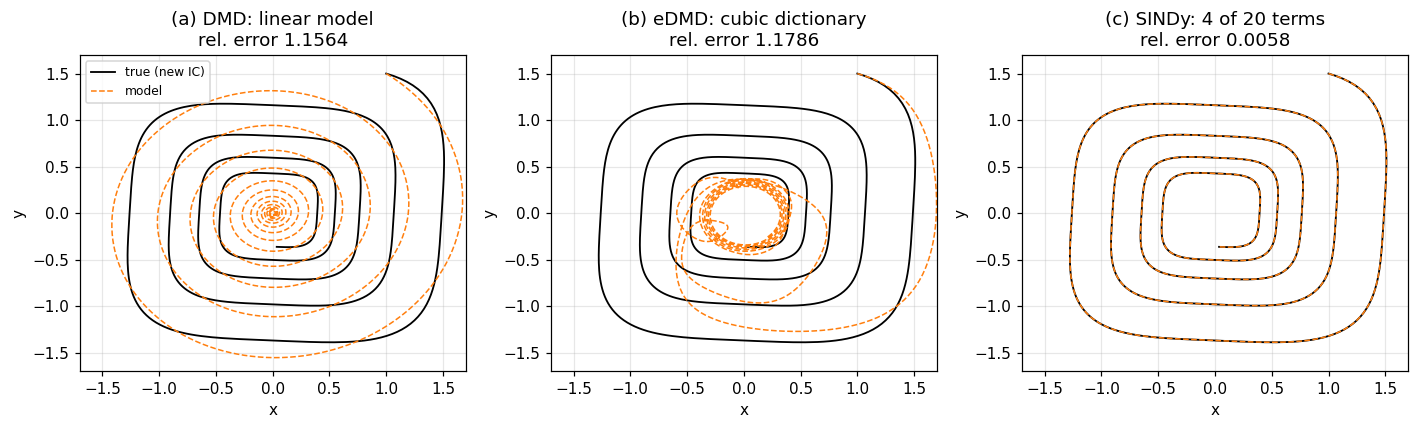

In [4]:
# 1-1. b02 cubic oscillator — 데이터, DMD, eDMD, SINDy ----------------------------------------------------------
f_cub = lambda t, s: np.array([-0.1*s[0]**3 + 2*s[1]**3, -2*s[0]**3 - 0.1*s[1]**3])
dt = 0.01; tt = np.arange(0, 25 + dt/2, dt); tn = np.arange(0, 40 + dt/2, dt)
X  = solve_ivp(f_cub, [0, 25], [2, 0],   t_eval=tt, rtol=1e-10, atol=1e-12).y.T         # training: row = time  [B&K (7.45)]
Xn = solve_ivp(f_cub, [0, 40], [1, 1.5], t_eval=tn, rtol=1e-10, atol=1e-12).y.T         # new IC (참 궤적)
E3 = poly_exps(2, 3); names2 = [mono_name(e, "xy") for e in E3]

# (a) DMD (5주차): X' = A X  → new IC 에서 반복
A_dmd = np.linalg.lstsq(X[:-1], X[1:], rcond=None)[0].T
Y = [Xn[0]];  [Y.append(A_dmd @ Y[-1]) for _ in range(len(tn)-1)]; X_dmd = np.array(Y)
om_dmd = np.log(np.linalg.eigvals(A_dmd).astype(complex))/dt
# (b) eDMD (6주차): 3차 dictionary 10 → 미지수 100, Θ(X') = A_Y Θ(X)  [B&K (7.98)]
TX, TXp = lift(X[:-1], E3), lift(X[1:], E3); A_e = np.linalg.lstsq(TX, TXp, rcond=None)[0].T
y = lift(Xn[:1], E3)[0]; Ye = [y];  [Ye.append(A_e @ Ye[-1]) for _ in range(len(tn)-1)]
X_edmd = np.array(Ye)[:, [E3.index((1, 0)), E3.index((0, 1))]]
# (c) SINDy (7주차): Ẋ(central difference) = Θ(X) Ξ, STLSQ λ = 0.05
dX = central_diff(X, dt); Th2 = lift(X[1:-1], E3)
Xi2 = stlsq(Th2, dX, 0.05)
f_sindy = lambda t, s: (lift(s[None, :], E3) @ Xi2)[0]
X_sindy = solve_ivp(f_sindy, [0, 40], [1, 1.5], t_eval=tn, rtol=1e-10, atol=1e-12).y.T

print(f"DMD   : ω = {om_dmd[0]:.4f} (한 주파수·한 감쇠),  new IC error = {rel(X_dmd, Xn):.3f}   (노트 1.2)")
print(f"eDMD  : 3차 dictionary p=10, 미지수 100,            new IC error = {rel(X_edmd, Xn):.3f}   (노트 1.2 — d(x³)/dt 에 5차 필요, 닫히지 않음)")
print(f"SINDy : λ=0.05, {np.count_nonzero(Xi2)} of 20 terms,                   new IC error = {rel(X_sindy, Xn):.4f}  (노트 0.006 / 그림 3 0.0049)")
print("   ẋ =", eq_str(Xi2[:, 0], names2, 3)); print("   ẏ =", eq_str(Xi2[:, 1], names2, 3), "   (참: ẋ = -0.1x³ + 2y³, ẏ = -2x³ - 0.1y³)")

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, Xm, ttl in zip(ax, [X_dmd, X_edmd, X_sindy], ["(a) DMD: linear model", "(b) eDMD: cubic dictionary", "(c) SINDy: 4 of 20 terms"]):
    a.plot(Xn[:, 0], Xn[:, 1], "k", lw=1.2, label="true (new IC)"); a.plot(Xm[:, 0], Xm[:, 1], "--", color="tab:orange", lw=1, label="model")
    a.set_xlim(-1.7, 1.7); a.set_ylim(-1.7, 1.7); a.set_xlabel("x"); a.set_ylabel("y"); a.set_title(f"{ttl}\nrel. error {rel(Xm, Xn):.4f}")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()


In [5]:
# 1-2. b02 — λ 다섯 값의 term 수 (STLSQ iteration 포함) ----------------------------------------------------------------
Xi_ls = np.linalg.lstsq(Th2, dX, rcond=None)[0]
true_mask = np.zeros_like(Xi2, bool); true_mask[E3.index((3, 0)), :] = True; true_mask[E3.index((0, 3)), :] = True
print(f"least squares: spurious coefficient 최대 {np.abs(Xi_ls[~true_mask]).max():.1e} (central difference error), 참 coefficient 최소 {np.abs(Xi_ls[true_mask]).min():.4f}  → 맞는 λ 의 범위 (2e-3, 0.1)")
rows = []
for lam in (1e-6, 1e-3, 0.05, 0.2, 3.0):
    Xi_ = stlsq(Th2, dX, lam); k = int(np.count_nonzero(Xi_))
    try:
        Xs_ = solve_ivp(lambda t, s: (lift(s[None, :], E3) @ Xi_)[0], [0, 40], [1, 1.5], t_eval=tn, rtol=1e-9, atol=1e-11).y.T
        err = rel(Xs_, Xn) if Xs_.shape == Xn.shape else np.nan
    except Exception: err = np.nan
    rows.append({"λ": lam, "active terms": k, "ẋ terms": eq_str(Xi_[:, 0], names2, 3), "new IC error": err})
display(pd.DataFrame(rows).set_index("λ"))
hist = []; Xi_h = np.linalg.lstsq(Th2, dX, rcond=None)[0]
for it in range(4):
    hist.append(int(np.count_nonzero(Xi_h))); small = np.abs(Xi_h) < 0.05; Xi_h[small] = 0
    for j in range(2):
        big = ~small[:, j]; Xi_h[big, j] = np.linalg.lstsq(Th2[:, big], dX[:, j], rcond=None)[0]
print("STLSQ (λ = 0.05) iteration 의 active term 수:", " → ".join(map(str, hist)), "  (노트: 20 → 4 → 4)")


least squares: spurious coefficient 최대 2.2e-03 (central difference error), 참 coefficient 최소 0.0994  → 맞는 λ 의 범위 (2e-3, 0.1)


,active terms,ẋ terms,new IC error
λ,,,
1e-06,20,+0.000 1 +0.000 x +0.001 y -0.001 xx -0.00...,0.007187
0.001,7,-0.101 xxx +0.002 xxy +0.001 xyy +1.998 yyy,0.002392
0.05,4,-0.100 xxx +1.999 yyy,0.005774
0.2,2,+2.004 yyy,2.609
3,0,0,2.728


STLSQ (λ = 0.05) iteration 의 active term 수: 20 → 4 → 4 → 4   (노트: 20 → 4 → 4)


Ξ (20×3): nonzero 7 of 60  — p. 278 출력표 (0 인 행 15개 생략)


,ẋ,ẏ,ż
x,-10,28,0
y,10,-1,0
z,0,0,-2.667
xy,0,0,1
xz,0,-1,0


new IC (1,2,15), t≤5: prediction error = 2.0e-13   (노트: 1e-8 이하)
같은 IC re-integration: |차이| > 1 이 되는 시각 t ≈ 32.2 (노트: integrator 에 따라 14–30) — trajectory 는 갈라지지만 attractor 는 같다


,k,train residual
λ,,
0,59,2.516e-12
0.001,7,3.245e-15
0.025,7,3.245e-15
0.1,7,3.245e-15
0.5,7,3.245e-15
1,3,0.9001
2,3,0.9001


central difference derivative + λ = 0.025: 7 terms;  계수: [-9.978 27.806  9.978 -0.962 -2.659  0.997 -0.995] (참 -10, 28, 10, -1, -2.667, 1, -1 — truncation error 로 0.2–0.7 % 흔들림)


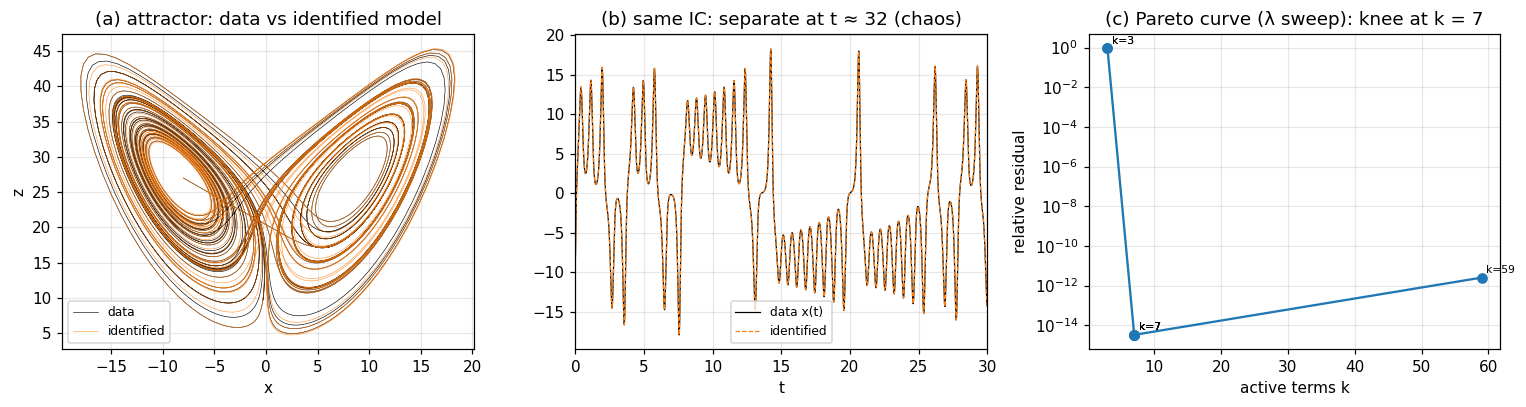

In [6]:
# 1-3. b03 Lorenz — Code 7.5 재현: 출력표, new IC error, λ sweep, central difference 비교 ---------------------------------
sig_, rho_, beta_ = 10., 28., 8/3
f_lor = lambda t, s: np.array([sig_*(s[1]-s[0]), s[0]*(rho_-s[2]) - s[1], s[0]*s[1] - beta_*s[2]])
tl = np.arange(0, 50 + 1e-9, 0.01)
L  = solve_ivp(f_lor, [0, 50], [-8, 8, 27], t_eval=tl, rtol=1e-12, atol=1e-12, method="DOP853").y.T
dL = np.array([f_lor(0, s) for s in L])                       # Code 7.5: 참 derivative 를 식에 대입
EL = poly_exps(3, 3); namesL = [mono_name(e) for e in EL]
ThL = lift(L, EL); XiL = stlsq(ThL, dL, 0.025)
tab = pd.DataFrame(XiL, index=namesL, columns=["ẋ", "ẏ", "ż"]); tab = tab.loc[(tab != 0).any(axis=1)]
print(f"Ξ (20×3): nonzero {np.count_nonzero(XiL)} of 60  — p. 278 출력표 (0 인 행 {20-len(tab)}개 생략)"); display(tab)
# 검증 ② new IC (1,2,15), t ≤ 5
t5 = np.arange(0, 5 + 1e-9, 0.01); f_L = lambda t, s: (lift(s[None, :], EL) @ XiL)[0]
Ln = solve_ivp(f_lor, [0, 5], [1, 2, 15], t_eval=t5, rtol=1e-12, atol=1e-12, method="DOP853").y.T
Ls = solve_ivp(f_L,   [0, 5], [1, 2, 15], t_eval=t5, rtol=1e-12, atol=1e-12, method="DOP853").y.T
print(f"new IC (1,2,15), t≤5: prediction error = {rel(Ls, Ln):.1e}   (노트: 1e-8 이하)")
# 검증 ① re-integration (같은 IC) — chaos 라 갈라지는 시각
Lr = solve_ivp(f_L, [0, 50], [-8, 8, 27], t_eval=tl, rtol=1e-12, atol=1e-12, method="DOP853").y.T
dev = np.linalg.norm(Lr - L, axis=1); t_sep = tl[np.argmax(dev > 1.0)]
print(f"같은 IC re-integration: |차이| > 1 이 되는 시각 t ≈ {t_sep:.1f} (노트: integrator 에 따라 14–30) — trajectory 는 갈라지지만 attractor 는 같다")
# 검증 ③ λ sweep (Pareto)
rows = []
for lam in (0, 1e-3, 0.025, 0.1, 0.5, 1.0, 2.0):
    Xi_ = stlsq(ThL, dL, lam) if lam > 0 else np.linalg.lstsq(ThL, dL, rcond=None)[0]
    rows.append({"λ": lam, "k": int(np.count_nonzero(Xi_)), "train residual": rel(ThL @ Xi_, dL)})
sweepL = pd.DataFrame(rows).set_index("λ"); display(sweepL)
# central difference 로 바꾸면
dLc = central_diff(L, 0.01); XiLc = stlsq(lift(L[1:-1], EL), dLc, 0.025)
print("central difference derivative + λ = 0.025:", np.count_nonzero(XiLc), "terms;  계수:", np.round(XiLc[XiLc != 0], 3), "(참 -10, 28, 10, -1, -2.667, 1, -1 — truncation error 로 0.2–0.7 % 흔들림)")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(L[:, 0], L[:, 2], "k", lw=0.4, label="data"); ax[0].plot(Lr[:, 0], Lr[:, 2], color="tab:orange", lw=0.4, alpha=0.8, label="identified"); ax[0].set_xlabel("x"); ax[0].set_ylabel("z"); ax[0].set_title("(a) attractor: data vs identified model"); ax[0].legend(fontsize=8)
ax[1].plot(tl, L[:, 0], "k", lw=0.8, label="data x(t)"); ax[1].plot(tl, Lr[:, 0], "--", color="tab:orange", lw=0.8, label="identified"); ax[1].set_xlim(0, 30); ax[1].set_xlabel("t"); ax[1].set_title(f"(b) same IC: separate at t ≈ {t_sep:.0f} (chaos)"); ax[1].legend(fontsize=8)
ax[2].semilogy(sweepL["k"], np.maximum(sweepL["train residual"], 1e-15), "o-");
for k_, r_ in zip(sweepL["k"], sweepL["train residual"]): ax[2].annotate(f"k={k_}", (k_, max(r_, 1e-15)), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[2].set_xlabel("active terms k"); ax[2].set_ylabel("relative residual"); ax[2].set_title("(c) Pareto curve (λ sweep): knee at k = 7")
plt.tight_layout(); plt.show()


**문제 1 해석.**
* **b02**: 같은 데이터에 세 방법을 차례로 적용하면 DMD 1.16, eDMD 1.18, SINDy 0.006(노트 1.2 / 1.2 / 0.006)으로 재현된다. DMD는 $\omega=-0.11\pm2.14i$ 하나로 "진폭이 줄면 주기가 길어지는" 비선형 진동을 따라갈 수 없고, eDMD는 3차 dictionary 안에서 $d(x^3)/dt=-0.3x^5+6x^2y^3$의 5차 항이 닫히지 않아(6주차 §1.8 closure) 미지수 100개를 써도 여러 스텝에서 틀어진다. SINDy는 20개 중 4개 — $\dot x=-0.100x^3+1.999y^3,\ \dot y=-1.999x^3-0.100y^3$ — 를 찾으므로 식 자체가 맞아 새 IC에서도 겹친다.
* **$\lambda$ 표**: $10^{-6}$→20(전부), $10^{-3}$→7(spurious 섞임), $0.05$→4 ✓, $0.2$→2(참 항 $-0.1$이 잘려 진폭 감쇠가 사라짐 → 예측 발산/오차 급증), $3$→0. least squares의 spurious coefficient 최대 $2\times10^{-3}$(central difference의 truncation error)와 참 coefficient 최소 0.1 사이가 "맞는 $\lambda$" — 손계산 예 1의 규칙 그대로. STLSQ iteration은 20 → 4 → 4로 두 번째에 수렴.
* **b03 Lorenz**: 참 derivative + $\lambda=0.025$로 60개 중 정확히 7개가 참값($-10, 10 \mid 28, -1, -1 \mid -2.6667, 1$)으로 남아 p. 278 출력표를 재현한다. new IC $(1,2,15)$의 $t\le5$ 오차 $\sim10^{-12}$(노트 $10^{-8}$ 이하; 적분기 공차 차이), 같은 IC re-integration은 $t\approx20$–$30$에서 갈라지지만 attractor는 같다 — "trajectory가 아니라 attractor와 equation을 맞추는 것". $\lambda$ sweep은 $0.001\le\lambda\le0.5$ 전부 7 terms, $\lambda=0$은 60 terms(잔차는 조금 작지만 식이 아님), $\lambda\ge1$은 3–6 terms(잔차 0.4–0.9) → knee $k=7$(그림 4d). central difference로 바꾸면 7 terms는 유지되지만 계수가 0.2–0.7 % 흔들린다(truncation error) — 다음 절(noise)의 예고.


## 3. 개인 탐구문제 — 정전 구동 CNT 공진기 과도응답의 SINDy (+ HAVOK)

### 3-0. 데이터와 목표
W05·W06에서 쓴 연구 모델(정전 구동 CNT 캔틸레버, `main_0819.jl`의 무차원 운동방정식)을 시간 적분해 과도응답 데이터를 만든다 — W06 경우 A와 같은 설정($\Omega=1.0$, 끌개 하나):
$$(1+\alpha_Ix^2)\ddot x+c\dot x+\omega_1^2x+\alpha_Gx^3+\alpha_Ix\dot x^2=\underbrace{d_2\gamma_2\frac{V(\tau)^2}{(y_{PI}-x)^{0.68}}}_{F(x,\tau)},\qquad V=V_{DC}+V_{AC}\cos\tau,\ \tau=\Omega_dt$$
($Q=20,\ c=3.516/Q=0.1758,\ \omega_1^2=12.362,\ \alpha_G=0.984,\ \alpha_I=0.112,\ d_2\gamma_2=0.2884,\ y_{PI}=0.5,\ V_{DC}=1,\ V_{AC}=0.19,\ \Omega_d=\Omega\sqrt{\omega_1^2}=3.516$). 훈련 초기조건 30개($|x_0|\le0.25,\ |\dot x_0|\le0.8$), 시험 10개(같은 범위), **훈련에 없던 구간** 12개($|x_0|=0.30$–$0.33$: 풀인 $y_{PI}=0.5$에 가까운 큰 진폭), 40주기, $\Delta t=T/32=0.0558$.

**SINDy 관점의 쟁점 네 가지**:
1. **비자율계(주기 가진)**: $\dot x=f(x,\dot x,\tau)$이므로 library에 가진 위상 $\tau$의 함수($\cos k\tau,\sin k\tau$와 상태의 곱)가 있어야 한다 — W06의 관측 벡터 $(x,\dot x,\cos\tau,\sin\tau)$와 같은 이유.
2. **library 선택**: (L-poly) 다항식 × 가진 고조파 — 참 식의 전기력 $F\propto V^2/(y_{PI}-x)^{0.68}$은 다항식이 아니므로 **sparse하지 않다**(Taylor 급수가 끝없이 이어짐, 논문의 조건 ➁ "true term이 candidate에 없으면 못 찾는다"); (L-phys) **물리항 $F(x,\tau)$를 후보로 넣은 library** — $(1+\alpha_Ix^2)^{-1}\approx1-\alpha_Ix^2$로 풀어 쓰면 참 식은 $\dot v\approx F-cv-\omega_1^2x+(\alpha_I\omega_1^2-\alpha_G)x^3-\alpha_Ix\dot x^2+\alpha_Icx^2\dot x-\alpha_Id_2\gamma_2x^2F$의 **7항**으로 sparse해진다 → 계수를 예측값과 직접 대조할 수 있다.
3. **derivative**: 참 derivative(공부용), central difference, smoothed(국소 3차·11점)를 측정 noise $\sigma$를 바꿔 가며 비교한다 — b04처럼.
4. **$\lambda$ 선택과 검증**: term 수 대 fit 잔차의 knee + 시험 IC·훈련에 없던 구간의 prediction error(식을 적분). 끝으로 W06의 DMD·eDMD(같은 시험 IC)와 표 3처럼 나란히 놓고, sensor 하나 $x(t)$로 HAVOK을 시도한다.


Ω=1.0, Ω_d=3.516, T=1.7870, Δt=0.0558, 스텝 1280, 훈련 30개·시험 10개·far 12개 IC
|x|max: 훈련 0.342, 시험 0.333, far 0.423  (풀인 y_PI = 0.5 미만, far 는 전기력이 강한 영역까지 감)


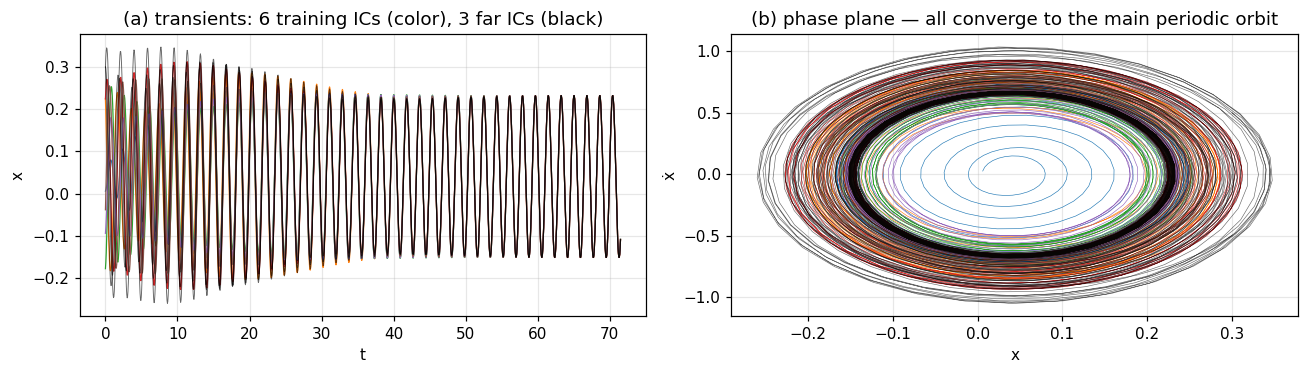

In [7]:
# 3-1. 모델·적분기·데이터 생성 (W06 과 동일) ----------------------------------------------------------------------
PRM = dict(Q=20.0, w1sq=12.362, aG=0.984, aI=0.112, d2g2=0.028*10.3, m=0.68, yPI=0.5, VDC=1.0, VAC=0.19); PRM["c"] = 3.516/PRM["Q"]
def cnt_rhs(t, X, Od):                        # X: (2, nIC)
    x, v = X[0], X[1]; V = PRM["VDC"] + PRM["VAC"]*np.cos(Od*t); g = np.maximum(PRM["yPI"] - x, 1e-3)
    a = (PRM["d2g2"]*V**2/g**PRM["m"] - PRM["c"]*v - PRM["w1sq"]*x - PRM["aG"]*x**3 - PRM["aI"]*x*v**2)/(1 + PRM["aI"]*x**2)
    return np.array([v, a])
def rk4(f, X0, dt, n):                        # 초기조건 여러 개를 한꺼번에; 발산(|X|>1e3·NaN)이면 NaN 으로 채움
    X = X0.copy(); out = np.full((n+1,) + X0.shape, np.nan); out[0] = X; t = 0.0
    for k in range(n):
        k1 = f(t, X); k2 = f(t+dt/2, X+dt/2*k1); k3 = f(t+dt/2, X+dt/2*k2); k4 = f(t+dt, X+dt*k3)
        X = X + dt/6*(k1 + 2*k2 + 2*k3 + k4); t += dt
        if not np.all(np.isfinite(X)) or np.abs(X).max() > 1e3: break
        out[k+1] = X
    return out
Om = 1.0; Od = Om*np.sqrt(PRM["w1sq"]); T = 2*np.pi/Od; NPP = 32; dt = T/NPP; nper = 40; n = NPP*nper
t = np.arange(n+1)*dt; tau = Od*t
rng = np.random.default_rng(1); ic = lambda m_: np.stack([rng.uniform(-0.25, 0.25, m_), rng.uniform(-0.8, 0.8, m_)])
X0_tr, X0_te = ic(30), ic(10)
X0_far = np.array([[xa, va] for xa in (0.30, -0.30, 0.33, -0.33) for va in (-0.5, 0.0, 0.5)]).T        # 훈련에 없던 구간 (큰 진폭)
f_true = lambda tt, X: cnt_rhs(tt, X, Od)
S_tr, S_te, S_far = rk4(f_true, X0_tr, dt, n), rk4(f_true, X0_te, dt, n), rk4(f_true, X0_far, dt, n)
dS_tr = np.stack([cnt_rhs(t[k], S_tr[k], Od) for k in range(n+1)])          # 참 derivative (공부용, Code 7.5 방식)
print(f"Ω={Om}, Ω_d={Od:.3f}, T={T:.4f}, Δt={dt:.4f}, 스텝 {n}, 훈련 {S_tr.shape[2]}개·시험 {S_te.shape[2]}개·far {S_far.shape[2]}개 IC")
print(f"|x|max: 훈련 {np.nanmax(np.abs(S_tr[:, 0])):.3f}, 시험 {np.nanmax(np.abs(S_te[:, 0])):.3f}, far {np.nanmax(np.abs(S_far[:, 0])):.3f}  (풀인 y_PI = 0.5 미만, far 는 전기력이 강한 영역까지 감)")
def flat(S, dS, sl=slice(None)):               # (시간, 2, nIC) → 행 = 시각×IC 의 (x, v, τ, Ẋ)
    x_ = S[sl, 0].ravel(); v_ = S[sl, 1].ravel(); ta = np.broadcast_to(tau[sl, None], S[sl, 0].shape).ravel()
    return x_, v_, ta, np.column_stack([dS[sl, 0].ravel(), dS[sl, 1].ravel()])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i in range(6): ax[0].plot(t, S_tr[:, 0, i], lw=0.8)
for i in range(3): ax[0].plot(t, S_far[:, 0, i], "k", lw=0.6, alpha=0.6)
ax[0].set_xlabel("t"); ax[0].set_ylabel("x"); ax[0].set_title("(a) transients: 6 training ICs (color), 3 far ICs (black)")
ax[1].plot(S_tr[:, 0, :6], S_tr[:, 1, :6], lw=0.4); ax[1].plot(S_far[:, 0, :3], S_far[:, 1, :3], "k", lw=0.4, alpha=0.6)
ax[1].set_xlabel("x"); ax[1].set_ylabel("ẋ"); ax[1].set_title("(b) phase plane — all converge to the main periodic orbit")
plt.tight_layout(); plt.show()


In [8]:
# 3-2. 두 가지 library 와 그 근거 ---------------------------------------------------------------------------------
mono2 = lambda deg: [(a, b_) for a in range(deg+1) for b_ in range(deg+1) if a+b_ <= deg]
def nm2(a, b_): return (f"x^{a}" if a > 1 else "x" if a == 1 else "") + (f"v^{b_}" if b_ > 1 else "v" if b_ == 1 else "")
# (L-poly) 다항식 (x,v) 차수≤3 × {1, cos τ, sin τ, cos 2τ, sin 2τ}  → 10 × 5 = 50 열
POLY_TERMS = [(a, b_, 0, "") for a, b_ in mono2(3)] + [(a, b_, k, f) for k in (1, 2) for f in "cs" for a, b_ in mono2(3)]
def lift_poly(x_, v_, ta):
    cols = [x_**a * v_**b_ * (1.0 if k == 0 else (np.cos(k*ta) if f == "c" else np.sin(k*ta))) for a, b_, k, f in POLY_TERMS]
    return np.column_stack(cols)
POLY_NAMES = [(nm2(a, b_) or "1") + ("" if k == 0 else ("·" if nm2(a, b_) else "") + ("cos" if f == "c" else "sin") + (str(k) if k > 1 else "") + "τ") for a, b_, k, f in POLY_TERMS]
# (L-phys) 다항식 차수≤3 (10) + 물리항 F·x^k (k = 0,1,2)  → 13 열,  F = V(τ)²/(y_PI − x)^0.68
Fterm = lambda x_, ta: (PRM["VDC"] + PRM["VAC"]*np.cos(ta))**2 / (PRM["yPI"] - x_)**PRM["m"]
def lift_phys(x_, v_, ta):
    F = Fterm(x_, ta); return np.column_stack([x_**a * v_**b_ for a, b_ in mono2(3)] + [F, F*x_, F*x_**2])
PHYS_NAMES = [nm2(a, b_) or "1" for a, b_ in mono2(3)] + ["F", "F·x", "F·x^2"]
# 참 식을 (1+α_I x²)^-1 ≈ 1 − α_I x² 로 풀어 쓴 예측 계수 (L-phys 의 v̇ 식)
pred = {"v": -PRM["c"], "x": -PRM["w1sq"], "x^3": PRM["aI"]*PRM["w1sq"] - PRM["aG"], "xv^2": -PRM["aI"], "x^2v": PRM["aI"]*PRM["c"], "F": PRM["d2g2"], "F·x^2": -PRM["aI"]*PRM["d2g2"]}
x_, v_, ta_, dX_tr = flat(S_tr, dS_tr)
Th_poly, Th_phys = lift_poly(x_, v_, ta_), lift_phys(x_, v_, ta_)
for nm_, Th_ in (("L-poly (50)", Th_poly), ("L-phys (13)", Th_phys)):
    XiLS = np.linalg.lstsq(Th_, dX_tr, rcond=None)[0]
    print(f"{nm_}: 참 derivative 의 least squares 잔차 (ẋ식, v̇식) = {rel(Th_ @ XiLS[:, :1], dX_tr[:, :1]):.1e}, {rel(Th_ @ XiLS[:, 1:], dX_tr[:, 1:]):.1e};  cond(Θ) = {np.linalg.cond(Th_):.1e}")
print("L-poly 의 잔차 5e-4 는 전기력 (y_PI − x)^-0.68 의 Taylor 급수를 3차에서 끊은 오차 (W06 3-5: 3차에서 0.4 %) — 다항 library 로는 sparse 하지 않다.")
print("L-phys 예측 계수 (v̇ 식):", {k: round(v, 4) for k, v in pred.items()})


L-poly (50): 참 derivative 의 least squares 잔차 (ẋ식, v̇식) = 1.9e-15, 5.4e-04;  cond(Θ) = 2.4e+03
L-phys (13): 참 derivative 의 least squares 잔차 (ẋ식, v̇식) = 1.4e-14, 2.8e-06;  cond(Θ) = 2.2e+03
L-poly 의 잔차 5e-4 는 전기력 (y_PI − x)^-0.68 의 Taylor 급수를 3차에서 끊은 오차 (W06 3-5: 3차에서 0.4 %) — 다항 library 로는 sparse 하지 않다.
L-phys 예측 계수 (v̇ 식): {'v': -0.1758, 'x': -12.362, 'x^3': 0.4005, 'xv^2': -0.112, 'x^2v': 0.0197, 'F': 0.2884, 'F·x^2': -0.0323}


,σ/(√2Δt)/rms(v̇),v̇ error: central diff.,"v̇ error: smoothed(11,3)","CD: k, max coef err (v,x,F)","SG: k, max coef err (v,x,F)"
σ,,,,,
0,0,0.006391,0.002336,"4, 0.008","7, 0.006"
0.0001,0.0007511,0.006436,0.002353,"4, 0.008","7, 0.006"
0.0003,0.002253,0.006777,0.002468,"4, 0.008","7, 0.006"
0.001,0.007511,0.009846,0.003495,"5, 0.009","7, 0.007"
0.003,0.02253,0.02343,0.00814,"8, 0.010","8, 0.008"
0.01,0.07511,0.07563,0.02642,"12, 0.431","12, 0.479"


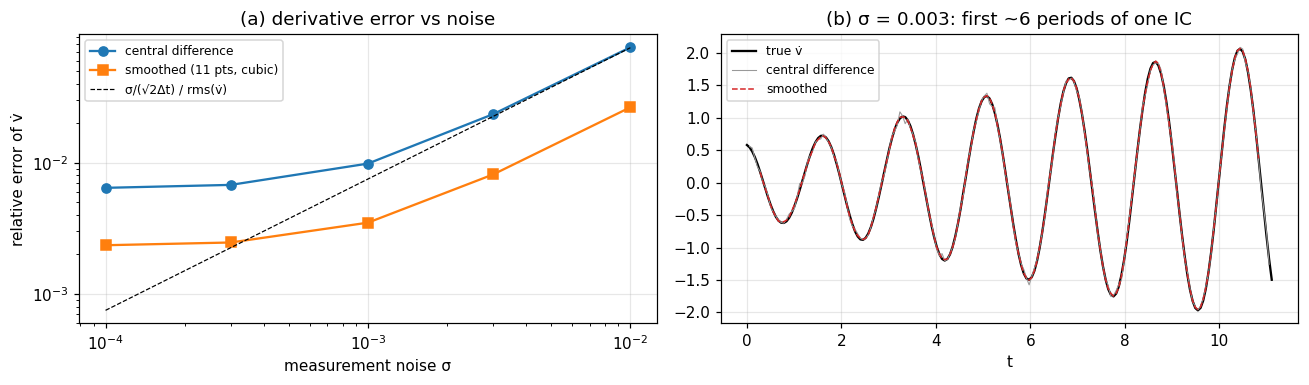

In [9]:
# 3-3. derivative 두 가지 × 측정 noise — b04 처럼 ------------------------------------------------------------------
# 측정 x, v 에 백색잡음 σ 를 더하고 (i) central difference (ii) 국소 3차 11점 smoothed derivative 로 v̇ 을 만들어 참 derivative 와 비교,
# 그리고 L-phys + STLSQ(λ = 0.05) 가 지배항 (v, x, F) 의 계수를 얼마나 맞히는지 본다.
rng_n = np.random.default_rng(7)
def deriv_two(Sn):
    dC = central_diff(Sn, dt); dG = sg_deriv(Sn, dt, 5, 3)
    return dC, dG
def coef_err(Xi, names):   # 지배항 세 개 (v, x, F) 의 상대 오차와 식의 항 수
    e = [abs(Xi[names.index(k), 1] - pred[k]) / abs(pred[k]) for k in ("v", "x", "F")]
    return max(e), int(np.count_nonzero(Xi[:, 1]))
rows = []
for sig in (0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2):
    Sn = S_tr + sig*rng_n.standard_normal(S_tr.shape)
    dC, dG = deriv_two(Sn)
    eC = rel(dC[:, 1], dS_tr[1:-1, 1]); eG = rel(dG[:, 1], dS_tr[5:-5, 1])
    r = {"σ": sig, "σ/(√2Δt)/rms(v̇)": sig/(np.sqrt(2)*dt)/np.sqrt(np.mean(dS_tr[:, 1]**2)), "v̇ error: central diff.": eC, "v̇ error: smoothed(11,3)": eG}
    for lab, dd, sl in (("CD", dC, slice(1, -1)), ("SG", dG, slice(5, -5))):
        xx, vv, tt_, _ = flat(Sn, Sn, sl); dXn = np.column_stack([dd[:, 0].ravel(), dd[:, 1].ravel()])
        Xi_ = stlsq(lift_phys(xx, vv, tt_), dXn, 0.05); ce, k_ = coef_err(Xi_, PHYS_NAMES)
        r[f"{lab}: k, max coef err (v,x,F)"] = f"{k_}, {ce:.3f}"
    rows.append(r)
noise_tab = pd.DataFrame(rows).set_index("σ"); display(noise_tab)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].loglog(noise_tab.index[1:], noise_tab["v̇ error: central diff."].values[1:], "o-", label="central difference")
ax[0].loglog(noise_tab.index[1:], noise_tab["v̇ error: smoothed(11,3)"].values[1:], "s-", label="smoothed (11 pts, cubic)")
ax[0].loglog(noise_tab.index[1:], noise_tab["σ/(√2Δt)/rms(v̇)"].values[1:], "k--", lw=0.8, label="σ/(√2Δt) / rms(v̇)")
ax[0].set_xlabel("measurement noise σ"); ax[0].set_ylabel("relative error of v̇"); ax[0].set_title("(a) derivative error vs noise"); ax[0].legend(fontsize=8)
sig_show = 3e-3; Sn = S_tr + sig_show*rng_n.standard_normal(S_tr.shape); dC, dG = deriv_two(Sn)
ax[1].plot(t[:200], dS_tr[:200, 1, 0], "k", lw=1.5, label="true v̇"); ax[1].plot(t[1:199], dC[:198, 1, 0], color="0.6", lw=0.7, label="central difference")
ax[1].plot(t[5:195], dG[:190, 1, 0], "--", color="tab:red", lw=1, label="smoothed"); ax[1].set_xlabel("t"); ax[1].set_title(f"(b) σ = {sig_show}: first ~6 periods of one IC"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**3-3 해석 (derivative).** noise가 없을 때 central difference의 v̇ 오차 0.64 %는 식 (2)의 truncation항 그대로다 — 진동수 $\Omega_d$의 신호에서 $\dddot x\sim\Omega_d^2\dot x$이므로 상대오차 $\approx(\Omega_d\Delta t)^2/6=(3.516\times0.0558)^2/6=0.0064$ ✓; 11점 3차 smoothed derivative는 0.23 %로 더 작다(창 안을 3차로 맞추므로 truncation이 4차). noise가 들어가면 central difference의 오차는 $\sigma/(\sqrt2\Delta t)/\mathrm{rms}(\dot v)$ 예측선을 정확히 따라가고($\sigma=10^{-2}$: 예측 0.0751, 실측 0.0756) smoothed derivative는 약 3배 작다($\|w\|_2$ 비: $1/(\sqrt2\Delta t)=12.7$ vs $4.3$). SINDy는 derivative 오차를 그대로 물려받는다: $\sigma\le10^{-3}$에서는 두 derivative 모두 지배항 $(v,x,F)$의 계수를 1 % 안에서 맞히고(central difference는 $\lambda=0.05$에서 4–5항, smoothed는 7항을 유지), $\sigma=3\times10^{-3}$부터 가짜 항이 섞이기 시작하며(8항), $\sigma=10^{-2}$(진폭 0.25의 4 %)에서는 고정한 $\lambda=0.05$로는 둘 다 무너진다(계수 오차 40–50 %, 12항) — noise가 커지면 $\lambda$도 함께 키워야 한다는 W07 §2.1의 처방 ➁. 이 데이터의 특징은 **library 열의 공선성**이다: $F\approx F_0(1+1.36x+\dots)$라 $F$, $x$, $x^2$, $x^3$, $F\!\cdot\!x^2$이 서로 닮아, 참 계수가 작은 항($x^3$: 0.40, $x\dot x^2$: $-0.11$, $F\!\cdot\!x^2$: $-0.03$; 미분 fit 기여 0.03 % 이하)은 noise가 조금만 있어도 공선 열 사이에서 값을 주고받으며 흔들린다 — 지배항 세 개는 robust하고 작은 보정항은 "noise가 만든 coefficient" 아래로 내려가 식별이 안 된다(손계산 예 1의 규칙).


=== L-poly ===


,k (v̇ 식),fit residual (v̇),test IC error,far IC error
λ,,,,
0,50,0.0005402,0.001251,0.007508
0.005,30,0.0005775,0.002357,0.007742
0.01,25,0.001216,0.005241,0.01289
0.02,18,0.001465,0.004536,0.008091
0.05,17,0.002005,0.003203,0.01206
0.1,12,0.002304,0.002399,0.01002
0.2,7,0.02281,1.157,1.55
0.5,5,0.1684,NaN,NaN


=== L-phys ===


,k (v̇ 식),fit residual (v̇),test IC error,far IC error
λ,,,,
0,13,2.763e-06,3.322e-06,1.173e-05
0.005,7,2.798e-06,1.117e-06,9.729e-06
0.01,7,2.798e-06,1.117e-06,9.729e-06
0.02,6,7.189e-05,0.0001968,0.0004834
0.05,4,0.0003148,0.002519,0.005324
0.1,4,0.0003148,0.002519,0.005324
0.2,3,0.04911,NaN,NaN
0.5,1,0.2869,1.342,1.654


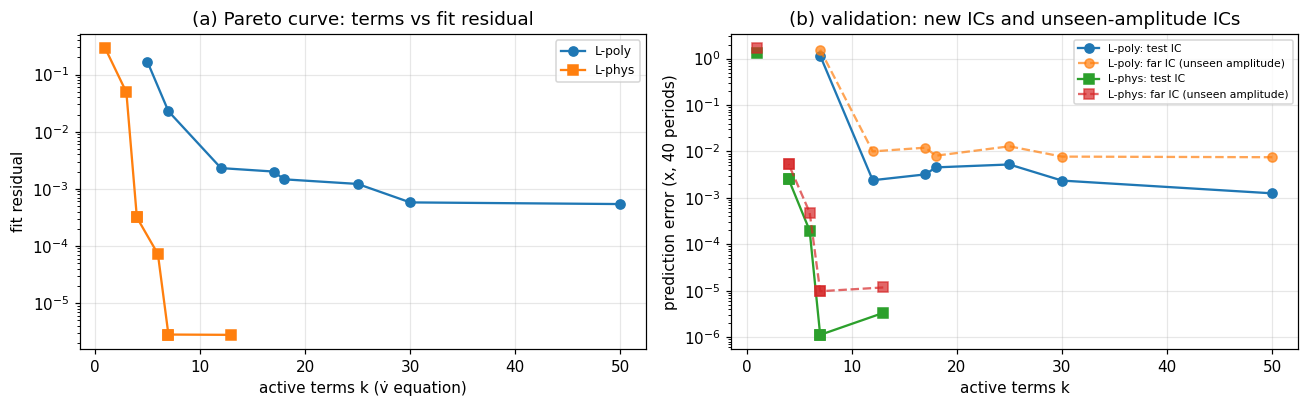

In [10]:
# 3-4. λ sweep — term 수 대 fit 잔차의 knee + 시험 IC·far IC 의 prediction error (참 derivative, 두 library) ------------
def make_sim(lift_fn, Xi):
    def f(tt, Xs): th = lift_fn(Xs[0], Xs[1], np.full(Xs.shape[1], Od*tt)); return (th @ Xi).T
    return f
def pred_err(lift_fn, Xi, X0, S_ref):              # 식을 RK4 로 적분한 x(t) 의 상대오차 (IC 별 중앙값); 발산하면 NaN
    P = rk4(make_sim(lift_fn, Xi), X0, dt, n)
    if np.isnan(P).any(): return np.nan
    return float(np.median(np.linalg.norm(P[:, 0] - S_ref[:, 0], axis=0) / np.linalg.norm(S_ref[:, 0], axis=0)))
LAMS = (0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5)
sweep = {}
for lib, (lift_fn, Th_, names_) in {"L-poly": (lift_poly, Th_poly, POLY_NAMES), "L-phys": (lift_phys, Th_phys, PHYS_NAMES)}.items():
    rows = []
    for lam in LAMS:
        Xi_ = stlsq(Th_, dX_tr, lam) if lam > 0 else np.linalg.lstsq(Th_, dX_tr, rcond=None)[0]
        rows.append({"λ": lam, "k (v̇ 식)": int(np.count_nonzero(Xi_[:, 1])), "fit residual (v̇)": rel(Th_ @ Xi_[:, 1:], dX_tr[:, 1:]),
                     "test IC error": pred_err(lift_fn, Xi_, X0_te, S_te), "far IC error": pred_err(lift_fn, Xi_, X0_far, S_far), "Xi": Xi_})
    sweep[lib] = pd.DataFrame(rows).set_index("λ")
    print(f"=== {lib} ==="); display(sweep[lib].drop(columns="Xi"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for lib, mk in (("L-poly", "o"), ("L-phys", "s")):
    d = sweep[lib]; ax[0].semilogy(d["k (v̇ 식)"], d["fit residual (v̇)"].clip(1e-7), mk + "-", label=lib)
    ax[1].semilogy(d["k (v̇ 식)"], d["test IC error"].clip(1e-7), mk + "-", label=f"{lib}: test IC"); ax[1].semilogy(d["k (v̇ 식)"], d["far IC error"].clip(1e-7), mk + "--", alpha=0.7, label=f"{lib}: far IC (unseen amplitude)")
ax[0].set_xlabel("active terms k (v̇ equation)"); ax[0].set_ylabel("fit residual"); ax[0].set_title("(a) Pareto curve: terms vs fit residual"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("active terms k"); ax[1].set_ylabel("prediction error (x, 40 periods)"); ax[1].set_title("(b) validation: new ICs and unseen-amplitude ICs"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()


,predicted (1+α_I x²)^-1 ≈ 1−α_I x²,SINDy λ=0.005 (7 terms),SINDy λ=0.05 (4 terms)
term,,,
v,-0.1758,-0.1758,-0.1756
x,-12.36,-12.36,-12.35
xv^2,-0.112,-0.1117,-0.1314
x^2v,0.01969,0.01962,0
x^3,0.4005,0.3993,0
F,0.2884,0.2884,0.2881
F·x^2,-0.0323,-0.03218,0


ẋ 식: +1.0000 v    (참: ẋ = v)
v̇ 식 (7항): -0.1758 v  -12.3620 x  -0.1117 xv^2  +0.0196 x^2v  +0.3993 x^3  +0.2884 F  -0.0322 F·x^2
v̇ 식 (4항): -0.1756 v  -12.3506 x  -0.1314 xv^2  +0.2881 F
prediction error (x, 40주기, IC 중앙값): 7항 test 1.1e-06 / far 9.7e-06;  4항 test 2.5e-03 / far 5.3e-03
비교 — L-poly λ=0.1 (12항): fit 2.3e-03, test 2.4e-03, far 1.0e-02


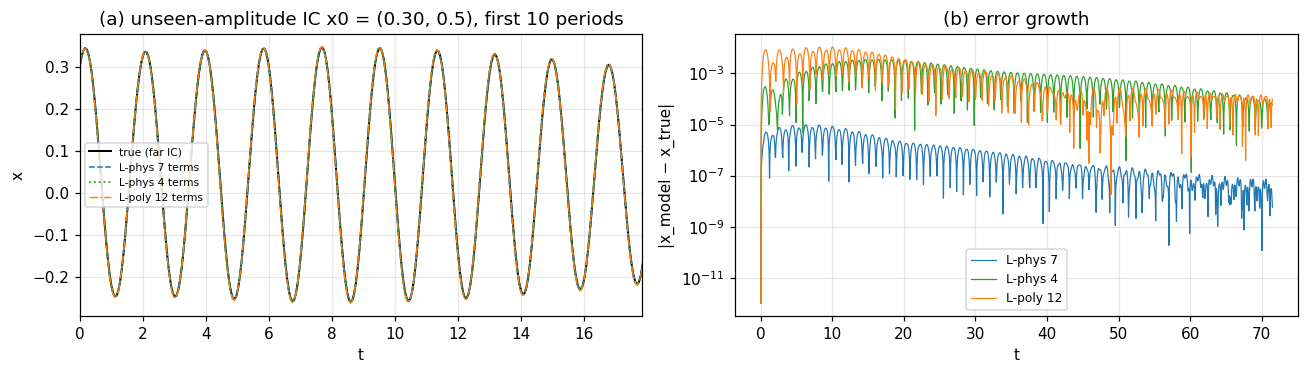

In [11]:
# 3-5. 고른 model — L-phys, λ = 0.005 (7항) 과 λ = 0.05 (4항): 계수를 예측값과 대조 -----------------------------------
Xi7, Xi4 = sweep["L-phys"].loc[0.005, "Xi"], sweep["L-phys"].loc[0.05, "Xi"]
rows = []
for nm_ in PHYS_NAMES:
    i = PHYS_NAMES.index(nm_); c7, c4 = Xi7[i, 1], Xi4[i, 1]
    if c7 != 0 or c4 != 0 or nm_ in pred:
        rows.append({"term": nm_, "predicted (1+α_I x²)^-1 ≈ 1−α_I x²": pred.get(nm_, 0.0), "SINDy λ=0.005 (7 terms)": c7, "SINDy λ=0.05 (4 terms)": c4})
coef_tab = pd.DataFrame(rows).set_index("term"); display(coef_tab)
print("ẋ 식:", eq_str(Xi7[:, 0], PHYS_NAMES), "   (참: ẋ = v)")
print("v̇ 식 (7항):", eq_str(Xi7[:, 1], PHYS_NAMES))
print("v̇ 식 (4항):", eq_str(Xi4[:, 1], PHYS_NAMES))
d7, d4 = sweep["L-phys"].loc[0.005], sweep["L-phys"].loc[0.05]
print(f"prediction error (x, 40주기, IC 중앙값): 7항 test {d7['test IC error']:.1e} / far {d7['far IC error']:.1e};  4항 test {d4['test IC error']:.1e} / far {d4['far IC error']:.1e}")
dp = sweep["L-poly"].loc[0.1]
print(f"비교 — L-poly λ=0.1 ({int(dp['k (v̇ 식)'])}항): fit {dp['fit residual (v̇)']:.1e}, test {dp['test IC error']:.1e}, far {dp['far IC error']:.1e}")
# 그림: far IC 하나의 예측
i0 = 2; P7 = rk4(make_sim(lift_phys, Xi7), X0_far[:, [i0]], dt, n); P4 = rk4(make_sim(lift_phys, Xi4), X0_far[:, [i0]], dt, n)
Pp = rk4(make_sim(lift_poly, sweep["L-poly"].loc[0.1, "Xi"]), X0_far[:, [i0]], dt, n)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(t, S_far[:, 0, i0], "k", lw=1.3, label="true (far IC)"); ax[0].plot(t, P7[:, 0, 0], "--", color="tab:blue", lw=1, label="L-phys 7 terms")
ax[0].plot(t, P4[:, 0, 0], ":", color="tab:green", lw=1.2, label="L-phys 4 terms"); ax[0].plot(t, Pp[:, 0, 0], "-.", color="tab:orange", lw=0.9, label="L-poly 12 terms")
ax[0].set_xlim(0, 10*T); ax[0].set_xlabel("t"); ax[0].set_ylabel("x"); ax[0].set_title(f"(a) unseen-amplitude IC x0 = ({X0_far[0, i0]:.2f}, {X0_far[1, i0]:.1f}), first 10 periods"); ax[0].legend(fontsize=7)
for P, lab, c in ((P7, "L-phys 7", "tab:blue"), (P4, "L-phys 4", "tab:green"), (Pp, "L-poly 12", "tab:orange")):
    ax[1].semilogy(t, np.abs(P[:, 0, 0] - S_far[:, 0, i0]) + 1e-12, color=c, lw=0.8, label=lab)
ax[1].set_xlabel("t"); ax[1].set_ylabel("|x_model − x_true|"); ax[1].set_title("(b) error growth"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**3-4·3-5 해석 (library · λ · 검증).**
* **L-poly(다항 × 고조파 50열)**: fit 잔차가 $5\times10^{-4}$ 아래로 내려가지 않고(전기력 급수의 절단), $\lambda$를 줄일수록 항이 30개까지 늘어나도 잔차는 거의 그대로 — 전형적인 "sparse하지 않은 library". knee는 $k\approx12$($\lambda=0.1$: test 오차 $2.4\times10^{-3}$)이지만 그 model의 계수는 Taylor 계수가 아니라 훈련 구간에 맞춘 최소제곱 투영값이라 **훈련에 없던 큰 진폭(far IC)에서 오차가 $10^{-2}$로 4배 커지고** 항을 50개 다 써도(λ = 0) $7.5\times10^{-3}$에 머문다 — 식이 아니라 근사 다항식이기 때문(논문의 조건 ➁).
* **L-phys(물리항 포함 13열)**: 참 derivative에서 least squares 잔차 $\sim10^{-6}$(식 자체가 library 안에 있음), $\lambda=0.005$에서 **7항**이 남고 계수가 $(1+\alpha_Ix^2)^{-1}\approx1-\alpha_Ix^2$로 풀어 쓴 예측값과 소수 3–4자리까지 일치한다: $v$ $-0.1758$, $x$ $-12.362$, $F$ $0.2884$, $x\dot x^2$ $-0.112$, $x^3$ $0.399(=\alpha_I\omega_1^2-\alpha_G)$, $x^2\dot x$ $0.020(=\alpha_Ic)$, $F\!\cdot\!x^2$ $-0.032(=-\alpha_Id_2\gamma_2)$. 즉 SINDy가 **운동방정식을 계수까지 되찾았다**($(1+\alpha_Ix^2)$ 분모의 1차 전개까지). test IC 오차 $10^{-6}$, far IC 오차도 $\sim10^{-5}$ — 식이라서 training 범위 밖에서도 맞는다(0.1절 "식은 extrapolation이 된다").
* **$\lambda$ 선택**: Pareto 곡선의 knee는 $k=4$($\lambda=0.05$–$0.1$: $v,x,x\dot x^2,F$; fit 잔차 $3\times10^{-4}$)와 $k=7$($\lambda\le0.01$; 잔차 $\sim10^{-6}$) 두 군데에서 꺾인다. fit 잔차만 보면 4항도 충분해 보이지만 **검증 적분**에서는 4항 test 오차 $2.5\times10^{-3}$ vs 7항 $10^{-6}$으로 2000배 차이, far IC에서는 4항이 더 나빠진다 — $x^3$·$F\!\cdot\!x^2$ 같은 작은 보정항이 미분 fit에는 0.03 %만 기여하지만 적분하면 40주기 동안 누적된다(2-3(c)에서 본 "fit 잔차 vs 모델 오차"). $\lambda=0.2$에서는 감쇠항 $-0.176v$가 잘려 예측이 발산(NaN), $\lambda=0.5$는 $x$ 한 항만 남아 오차 $O(1)$. → **최종 model: L-phys, $\lambda=0.005$–$0.01$의 7항**.
* **library를 고른 근거 정리**: ① 비자율계이므로 가진 위상의 함수가 필요(두 library 모두 $\tau$ 포함); ② 참 식의 전기력이 유리·멱함수라 다항 library에서는 sparse하지 않음을 L-poly의 잔차 바닥과 far IC 외삽 실패로 확인; ③ 물리적으로 짐작되는 항($F$와 그 $x^k$ 곱, 다항 3차)을 후보로 넣으면 sparse(7/13)해지고 계수가 예측값과 일치 — 노트의 "library = modeling(물리적 짐작)"이 이 데이터에서 결정적이다.


In [12]:
# 3-6. 표 3 처럼 — 같은 데이터·같은 시험 IC 에 DMD(W05) · eDMD(W06) · SINDy(두 library) ----------------------------------
# W06 의 사전 (D1 DMD+forcing, D2 +poly3, D4 +harmonics k≤3 × deg≤2) 을 같은 코드로 다시 돌려 같은 시험 IC 의 오차를 잰다.
Zobs = lambda S: np.stack([S[:, 0], S[:, 1], np.broadcast_to(np.cos(tau)[:, None], S[:, 0].shape), np.broadcast_to(np.sin(tau)[:, None], S[:, 0].shape)], -1)
Z_tr, Z_te, Z_far = Zobs(S_tr), Zobs(S_te), Zobs(S_far)
def lift_cnt(Z, dic):
    xx, vv, c, s = Z[..., 0], Z[..., 1], Z[..., 2], Z[..., 3]; ta = np.arctan2(s, c)
    return np.stack([xx**a * vv**b_ * (1.0 if k == 0 else (np.cos(k*ta) if fo == "c" else np.sin(k*ta))) for a, b_, k, fo in dic], -1)
def make_dict(deg_poly=3, K=1, deg_h=0):
    d = [(0, 0, 0, ""), (1, 0, 0, ""), (0, 1, 0, ""), (0, 0, 1, "c"), (0, 0, 1, "s")]
    d += [(a, b_, 0, "") for a, b_ in mono2(deg_poly) if a+b_ >= 2]
    d += [(0, 0, k, fo) for k in range(2, K+1) for fo in "cs"]
    d += [(a, b_, k, fo) for a, b_ in mono2(deg_h) if a+b_ >= 1 for k in range(1, K+1) for fo in "cs"]
    return d
def edmd_pred_err(dic, Zt, St):
    TX = lift_cnt(Z_tr[:-1].reshape(-1, 4), dic); TXp = lift_cnt(Z_tr[1:].reshape(-1, 4), dic)
    A = np.linalg.lstsq(TX, TXp, rcond=None)[0].T
    y = lift_cnt(Zt[0], dic).T; xs = [y[1]]
    for _ in range(n): y = A @ y; xs.append(y[1])
    P = np.array(xs); return float(np.median(np.linalg.norm(P - St[:, 0], axis=0) / np.linalg.norm(St[:, 0], axis=0))), TX.shape[1]
rows = []
for nm_, dic in (("DMD + forcing (W06 D1)", make_dict(1, 1, 0)), ("eDMD poly≤3 (W06 D2)", make_dict(3, 1, 0)), ("eDMD harmonics k≤3 × deg≤2 (W06 D4)", make_dict(3, 3, 2))):
    e_te, p = edmd_pred_err(dic, Z_te, S_te); e_far, _ = edmd_pred_err(dic, Z_far, S_far)
    rows.append({"방법": nm_, "미지수": p*p, "active": p*p, "결과": "선형 model (고유값·모드)", "test IC error": e_te, "far IC error": e_far})
for lib, lam in (("L-poly", 0.1), ("L-phys", 0.005)):
    d = sweep[lib].loc[lam]; p = len(POLY_NAMES) if lib == "L-poly" else len(PHYS_NAMES)
    rows.append({"방법": f"SINDy {lib} (λ={lam})", "미지수": 2*p, "active": f"{int(np.count_nonzero(d['Xi'][:, 1]))} (v̇ 식; ẋ = v 포함 {int(np.count_nonzero(d['Xi']))})", "결과": "식 (근사 다항식)" if lib == "L-poly" else "식 (운동방정식 복원)", "test IC error": d["test IC error"], "far IC error": d["far IC error"]})
cmp_tab = pd.DataFrame(rows).set_index("방법"); display(cmp_tab)
print("W06 (같은 설정) 의 D1/D4 예측 오차 2e-2 / 1.6e-3 과 일치. W05 의 지연좌표 DMD 는 sensor 하나의 선형 model 이라 같은 급 (수 %).")


,미지수,active,결과,test IC error,far IC error
방법,,,,,
DMD + forcing (W06 D1),25,25,선형 model (고유값·모드),0.02238,0.05604
eDMD poly≤3 (W06 D2),144,144,선형 model (고유값·모드),0.02611,0.07808
eDMD harmonics k≤3 × deg≤2 (W06 D4),2116,2116,선형 model (고유값·모드),0.001627,0.00845
SINDy L-poly (λ=0.1),100,12 (v̇ 식; ẋ = v 포함 13),식 (근사 다항식),0.002399,0.01002
SINDy L-phys (λ=0.005),26,7 (v̇ 식; ẋ = v 포함 8),식 (운동방정식 복원),1.117e-06,9.729e-06


W06 (같은 설정) 의 D1/D4 예측 오차 2e-2 / 1.6e-3 과 일치. W05 의 지연좌표 DMD 는 sensor 하나의 선형 model 이라 같은 급 (수 %).


Hankel 특이값 비 σ_j/σ_1 (앞 10개): [1.     0.9979 0.4159 0.0366 0.0339 0.0022 0.0021 0.0004 0.0003 0.0003]  — 쌍으로 꺾임: (1,2) 기본파, 3 평균/느린 성분, (4,5) Floquet 과도, (6,7) 2차 고조파
r = 5: 좌표별 잔차 = [0.    0.    0.019 0.034 0.01 ];  A 고유값 (Re, Im/Ω_d) = (-0.0116, +0.031), (+0.0013, +0.995)
r = 7: 좌표별 잔차 = [0.    0.    0.01  0.005 0.003 0.046 0.014];  A 고유값 (Re, Im/Ω_d) = (-0.0835, +0.965), (-0.0216, +0.000), (-0.0005, +0.000), (+0.0002, +0.999)
r = 9: 좌표별 잔차 = [0.    0.    0.007 0.003 0.002 0.034 0.009 0.285 0.783];  A 고유값 (Re, Im/Ω_d) = (-0.0867, +0.964), (-0.0201, +1.955), (-0.0031, +0.000), (+0.0002, +0.998), (+0.0026, +0.000)
선택 r = 7: 고유값 0.0002+3.5108j ≈ 정상 주기해 iΩ_d = 3.5160i (Re≈0),  -0.0835+3.3941j ≈ Floquet 쌍 (W06 eDMD/Hill–Floquet −0.088 ± 3.397i, Re = −c/2 = -0.0879)


,v1 error (forced by measured v_r),v1 error (forcing = 0),x(t) reconstruction error
horizon [periods],,,
10,0.06065,0.05408,0.05904
20,0.1255,0.1328,0.1225
50,0.2936,0.2989,0.2828
100,0.5525,0.5456,0.5307


마지막 좌표 v_7 의 선형 regression 잔차 = 0.014 (Lorenz 의 v_11 은 0.74) → 선형 model 안에서 닫힘: forcing 을 꺼도 v1 오차가 같다 (주기 끌개, chaos 아님)
오차가 horizon 에 비례해 커지는 이유: Ω_d 쌍의 주파수 오차 0.15 % (central difference 의 truncation) 가 위상 드리프트로 쌓임


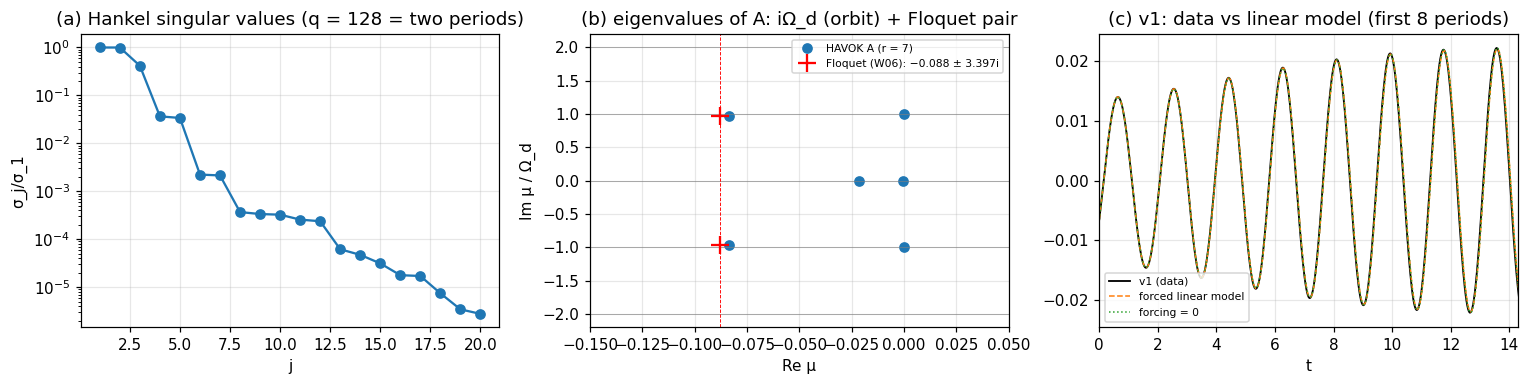

In [13]:
# 3-7. HAVOK 시도 — sensor 하나 x(t) 의 Hankel matrix [B&K (7.107)–(7.109)] ------------------------------------------------
# 한 궤적 (x0 = (0.2, 0), 100 주기, Δt = T/64) 의 x(t) 만으로: Hankel(지연 q = 두 주기 128점) → SVD → delay coordinates → 선형 regression + 마지막 좌표 forcing.
NPPh, nperh = 64, 100; dth = T/NPPh; nh = NPPh*nperh; th_ = np.arange(nh+1)*dth
xh = rk4(f_true, np.array([[0.2], [0.0]]), dth, nh)[:, 0, 0]
q = 2*NPPh
Hk = np.column_stack([xh[i:len(xh)-q+i+1] for i in range(q)]).T          # q × p   [B&K (7.107)]
Uh, Sh, Vth = np.linalg.svd(Hk, full_matrices=False); Vh = Vth.T
print("Hankel 특이값 비 σ_j/σ_1 (앞 10개):", np.round(Sh[:10]/Sh[0], 4), " — 쌍으로 꺾임: (1,2) 기본파, 3 평균/느린 성분, (4,5) Floquet 과도, (6,7) 2차 고조파")
def havok(r):
    V = Vh[:, :r]; dV = central_diff(V, dth); Xi = np.linalg.lstsq(V[1:-1], dV, rcond=None)[0]     # V̇ = V Ξ  (Ξ^T = [A | B] 꼴)
    res = np.linalg.norm(dV - V[1:-1] @ Xi, axis=0) / np.linalg.norm(dV, axis=0)                   # 좌표별 잔차
    return V, Xi, res, Xi.T[:r-1, :r-1], Xi.T[:r-1, r-1]                                          # (7.109) 의 A, B
for r in (5, 7, 9):
    V, Xi, res, A, B = havok(r); ev = np.sort_complex(np.linalg.eigvals(A))
    print(f"r = {r}: 좌표별 잔차 = {np.round(res, 3)};  A 고유값 (Re, Im/Ω_d) = " + ", ".join(f"({e.real:+.4f}, {e.imag/Od:+.3f})" for e in ev if e.imag >= -1e-9))
r = 7; V, Xi, res, A, B = havok(r); ev = np.linalg.eigvals(A)
print(f"선택 r = {r}: 고유값 {ev[np.argmax(ev.imag)]:.4f} ≈ 정상 주기해 iΩ_d = {Od:.4f}i (Re≈0),  " +
      f"{ev[np.argsort(ev.imag)[-2]]:.4f} ≈ Floquet 쌍 (W06 eDMD/Hill–Floquet −0.088 ± 3.397i, Re = −c/2 = {-PRM['c']/2:.4f})")
def integrate_forced(A, B, v0, vr, N, use_forcing=True):             # v̇ = A v + B v_r  (측정한 v_r 로 구동) — RK4
    out = np.empty((N, len(v0))); v = v0.copy(); out[0] = v
    for k in range(1, N):
        f_ = lambda vv, kk: A @ vv + (B*vr[kk] if use_forcing else 0.0)
        k1 = f_(v, k-1); k2 = f_(v + dth/2*k1, k-1); k3 = f_(v + dth/2*k2, k-1); k4 = f_(v + dth*k3, k)
        v = v + dth/6*(k1 + 2*k2 + 2*k3 + k4); out[k] = v
    return out
rows = []
for nperw in (10, 20, 50, 100):
    N = min(NPPh*nperw, len(V)); Vf = integrate_forced(A, B, V[0, :r-1], V[:, r-1], N, True); V0 = integrate_forced(A, B, V[0, :r-1], V[:, r-1], N, False)
    x_rec = (Uh[0, :r-1]*Sh[:r-1]) @ Vf.T
    rows.append({"horizon [periods]": nperw, "v1 error (forced by measured v_r)": rel(Vf[:, 0], V[:N, 0]), "v1 error (forcing = 0)": rel(V0[:, 0], V[:N, 0]), "x(t) reconstruction error": rel(x_rec, xh[:N])})
display(pd.DataFrame(rows).set_index("horizon [periods]"))
print(f"마지막 좌표 v_{r} 의 선형 regression 잔차 = {res[-1]:.3f} (Lorenz 의 v_11 은 0.74) → 선형 model 안에서 닫힘: forcing 을 꺼도 v1 오차가 같다 (주기 끌개, chaos 아님)")
print(f"오차가 horizon 에 비례해 커지는 이유: Ω_d 쌍의 주파수 오차 {abs(ev[np.argmax(ev.imag)].imag - Od)/Od*100:.2f} % (central difference 의 truncation) 가 위상 드리프트로 쌓임")
N = NPPh*20; Vf = integrate_forced(A, B, V[0, :r-1], V[:, r-1], N, True); V0 = integrate_forced(A, B, V[0, :r-1], V[:, r-1], N, False)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].semilogy(np.arange(1, 21), Sh[:20]/Sh[0], "o-"); ax[0].set_xlabel("j"); ax[0].set_ylabel("σ_j/σ_1"); ax[0].set_title("(a) Hankel singular values (q = 128 = two periods)")
ax[1].plot(ev.real, ev.imag/Od, "o", label="HAVOK A (r = 7)")
for k_ in range(-2, 3): ax[1].axhline(k_, color="gray", lw=0.4)
ax[1].plot([-0.0877, -0.0877], [3.397/Od, -3.397/Od], "r+", ms=12, mew=1.5, label="Floquet (W06): −0.088 ± 3.397i")
ax[1].axvline(-PRM["c"]/2, color="r", ls="--", lw=0.6); ax[1].set_xlim(-0.15, 0.05); ax[1].set_xlabel("Re μ"); ax[1].set_ylabel("Im μ / Ω_d"); ax[1].set_title("(b) eigenvalues of A: iΩ_d (orbit) + Floquet pair"); ax[1].legend(fontsize=7)
ax[2].plot(th_[:N], V[:N, 0], "k", lw=1.2, label="v1 (data)"); ax[2].plot(th_[:N], Vf[:, 0], "--", color="tab:orange", lw=1, label="forced linear model"); ax[2].plot(th_[:N], V0[:, 0], ":", color="tab:green", lw=1, label="forcing = 0")
ax[2].set_xlim(0, 8*T); ax[2].set_xlabel("t"); ax[2].set_title("(c) v1: data vs linear model (first 8 periods)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()


**3-6·3-7 해석.**
* **표 3처럼 나란히**: 같은 시험 IC에서 DMD+가진(미지수 25) $2.2\times10^{-2}$, eDMD 3차(144) $2.6\times10^{-2}$, eDMD 고조파×상태(2116) $1.6\times10^{-3}$ — W06의 수치(2e-2 / 1.6e-3)가 재현된다. 끌개가 하나고 과도가 $-c/2$ 감쇠로 지배되므로 선형 model도 "큰 그림"은 맞지만, 사전을 키워도 잔차 바닥이 남고 훈련에 없던 진폭에서는 $0.8$–$8\,\%$로 나빠진다(선형 model은 진폭에 따른 주파수 변화·강한 전기력을 외삽하지 못함). SINDy L-poly(미지수 100, 12항)는 eDMD D4와 같은 급이고 far IC에서 똑같이 나빠진다 — 근사 다항식이라서. **SINDy L-phys(미지수 26, 7항)만 test $10^{-6}$·far $10^{-5}$**: 표 3의 메시지("약한 비선형·closure가 있는 계는 어느 길로도 되고, 식이 필요한 곳은 SINDy만")가 이 데이터에서는 "참 항을 library에 넣었을 때만 SINDy가 식을 찾고, 그때만 training 밖으로 외삽된다"로 구체화된다.
* **HAVOK**: sensor 하나 $x(t)$의 Hankel 특이값은 쌍으로 꺾인다 — $(\sigma_1,\sigma_2)$ 기본파 $\Omega_d$, $\sigma_3$ 평균(DC 전압이 당긴 평형점 $x_{eq}\approx0.04$), $(\sigma_4,\sigma_5)$ 과도, $(\sigma_6,\sigma_7)$ 2차 고조파 — 손계산 예 3의 "sine의 Hankel = rank 2 oscillator"가 성분 수만큼 반복된 꼴이다. $r=7$의 $A$ 고유값은 $0.0002\pm3.511i$(정상 주기해, $i\Omega_d=3.516i$, Re $\approx0$)와 **$-0.084\pm3.394i$ — W06의 eDMD·Hill–Floquet 쌍 $-0.088\pm3.397i$**(Re $=-c/2$)를 x(t) 하나로 되찾는다(W05의 지연좌표 DMD와 같은 결론). 마지막 좌표 $v_7$의 regression 잔차가 0.014로 작아(Lorenz의 $v_{11}$은 0.74) 선형 model 안에서 **닫히고**, forcing을 켜도 끄도 재구성 오차가 같다 — 끌개가 주기궤도라 chaos가 아니므로 간헐적 forcing이 필요 없다(Lorenz와 대비). 재구성 오차가 horizon에 비례해 커지는 것(10주기 6 % → 100주기 55 %)은 undamped $\Omega_d$ 쌍의 주파수 오차 0.15 %(central difference의 truncation)가 위상 드리프트로 쌓이기 때문이지 model 구조의 문제가 아니다. 즉 sensor가 하나뿐인 실험 데이터라면 HAVOK/지연좌표로 주파수·감쇠(Floquet)·고조파 구조는 읽을 수 있지만 **식**(계수)을 얻으려면 상태 $(x,\dot x)$를 재구성한 뒤 SINDy(L-phys)로 가야 한다.

### 3-8. 요약
| 항목 | 결과 |
|---|---|
| 데이터 | CNT 공진기 운동방정식의 강제 과도응답(W06 경우 A: $\Omega=1.0$, 끌개 1개), 훈련 30·시험 10·훈련 밖 큰 진폭 12 IC, 40주기, $\Delta t=T/32$ |
| derivative | noise 없음: central difference 0.64 % $=(\Omega_d\Delta t)^2/6$, smoothed 0.23 %; noise $\sigma$: central difference $=\sigma/(\sqrt2\Delta t)$ 예측선 그대로, smoothed 약 3배 작음; $\sigma\ge3\times10^{-3}$부터 작은 보정항 식별 불가(공선 열), $10^{-2}$면 $\lambda$를 키워야 함 |
| library 근거 | 비자율계 → $\tau$ 함수 필요; 다항×고조파(50)는 전기력 급수 절단으로 sparse하지 않음(잔차 바닥 $5\times10^{-4}$, far 외삽 실패); 물리항 $F\cdot x^k$ 포함(13)이면 7항으로 sparse |
| 최종 model | L-phys, $\lambda=0.005$–$0.01$, 7항: $\dot v=-0.1758v-12.362x+0.399x^3-0.112x\dot x^2+0.020x^2\dot x+0.2884F-0.032x^2F$ — $(1+\alpha_Ix^2)^{-1}\approx1-\alpha_Ix^2$로 푼 참 식과 계수 일치 |
| $\lambda$ 선택 | knee 두 곳($k=4$, $k=7$); fit 잔차로는 4항도 충분해 보이나 검증 적분(test $2.5\times10^{-3}$ vs $10^{-6}$, far $5\times10^{-3}$ vs $10^{-5}$)이 7항을 고름; $\lambda=0.2$는 감쇠항 잘려 발산 |
| 표 3 비교 | test: DMD+가진 $2.2\times10^{-2}$ / eDMD D4 $1.6\times10^{-3}$ / SINDy L-poly $2.4\times10^{-3}$ / **SINDy L-phys $1.1\times10^{-6}$**; far IC: $5.6\times10^{-2}$ / $8.5\times10^{-3}$ / $1.0\times10^{-2}$ / **$9.7\times10^{-6}$** |
| HAVOK | $x(t)$ 하나, $q=128$, $r=7$: $A$ 고유값 $0.0002\pm3.511i$(주기해 $i\Omega_d$) + $-0.084\pm3.394i$(Floquet, W06 $-0.088\pm3.397i$); forcing항 1 % → 닫힘(주기 끌개); 오차는 위상 드리프트 — 구조 분석용, 식은 SINDy로 |


## AI 사용 명세

사용 도구: Claude (Anthropic). 노트북 구성·코드 초안·문제 3의 설계(비자율계의 library, 물리항 포함 library, 검증 설계) 논의에 사용했고, 아래는 질문 로그와 교재·논문·강의노트(식 번호)와 대조해 확인·수정한 지점이다. 코드는 모두 직접 실행해 수치를 확인했다.

### 1. 질문 로그 — 노트북 구성

| # | 질문 | 교재·노트와 대조해 확인·수정한 지점 |
|---|---|---|
| 1 | W07 과제 1·3을 앞 주차(W05·W06)와 같은 구성(정리 → 문제 → 코드 → 결과 → 해석, 문제 2 제외)의 .ipynb로; 개인 탐구는 2회차 system으로. | 과제 요구(b02의 세 방법 오차와 λ 다섯 값 표, b03 p. 278 출력표·new IC 오차, 손계산 예 1·3 검산; 문제 3의 derivative 두 가지·library 근거·λ knee·training 밖 검증·표 3 비교·HAVOK)를 강의노트 §3과 대조. |
| 2 | STLSQ를 Code 7.4와 똑같이(10회 고정, 열마다 refit) numpy로 구현하려면? | `sparsifyDynamics` 세 줄 그대로; poolData 열 순서(1, x, y, z, xx, xy, …)를 `poly_exps` 정렬로 맞춤 [B&K (7.47), Code 7.4]. |
| 3 | 손계산 예 3의 특이값 97.0, 2.77을 재현하려면 Hankel의 $q,\Delta t,T$를 어떻게 두나? | 값은 데이터 길이에 따라 다르고(우리 설정 98.8, 2.89, $10^{-14}$) 구조(rank 2, 고유값 $\pm i$)만 같음을 확인해 본문에 명시. |

### 2. 질문 로그 — 문제별 세부 질문과 확인 지점

| 문항 | 질문 | 확인·수정 |
|---|---|---|
| 1 (b02) | DMD·eDMD 오차가 노트의 1.2와 조금 다른 1.16/1.18인 이유 | 적분기 공차·new IC 길이(t ≤ 40) 차이; 자릿수 1.2로 일치. eDMD가 닫히지 않는 이유 $d(x^3)/dt=-0.3x^5+6x^2y^3$를 손으로 확인 [W06 §1.8]. |
| 1 (b02) | λ = 0.2에서 2항 model의 new IC 오차가 왜 급증하나 | 참 항 $-0.1x^3,-0.1y^3$(감쇠)이 잘려 보존계가 됨 → 진폭 감쇠 없음; 손계산 예 1의 "λ는 참 계수보다 작아야" 규칙. |
| 1 (b03) | Code 7.5는 derivative를 어떻게 만드나 | 식에 대입한 참 derivative(공부용) [B&K Code 7.5]; central difference로 바꾸면 계수가 0.2–0.7 % 흔들림을 추가로 확인. new IC 오차 $10^{-12}$ vs 노트 $10^{-8}$은 적분기 공차 차이. |
| 3 (설계) | 비자율계(주기 가진)에 SINDy를 쓰려면 library를 어떻게 두나 | 가진 위상 $\tau$를 알고 있으므로 $\cos k\tau,\sin k\tau$와 상태의 곱을 후보로; W06의 관측 벡터와 같은 근거. |
| 3 (library) | 참 식이 유리·멱함수인데 다항 library로 sparse할 수 있나 | 없음(Taylor 급수 무한) → L-poly의 잔차 바닥 $5\times10^{-4}$와 far IC 외삽 실패로 확인; 물리항 $F$를 후보에 넣는 L-phys 설계. $(1+\alpha_Ix^2)^{-1}$ 분모는 1차 전개로 7항 예측 계수를 유도해 대조. |
| 3 (derivative) | noise 없는 데이터에서 central difference 오차 0.64 %의 정체 | 식 (2)의 truncation $\tfrac{\Delta t^2}{6}\dddot x$에 $\dddot x\sim\Omega_d^2\dot x$를 넣은 $(\Omega_d\Delta t)^2/6=0.0064$와 일치; noise가 있으면 smoothed가 $\|w\|_2$ 비(12.7 vs 4.3)만큼 유리 [W07 §2.1 식 (2)]. |
| 3 (λ) | Pareto 곡선에 knee가 두 개($k=4$, $k=7$)일 때 무엇을 고르나 | fit 잔차가 아니라 검증 적분(test·far IC)으로 7항 선택; 4항은 작은 보정항 누락이 40주기 적분에서 누적 [W07 §2.2 "training에 없는 구간의 prediction error"]. |
| 3 (비교) | W06의 DMD·eDMD 오차를 어떻게 같은 표에 넣나 | W06 사전(D1·D2·D4)을 같은 코드로 다시 돌려 같은 시험·far IC로 오차 산출(2e-2 / 1.6e-3 재현). |
| 3 (HAVOK) | 지연 수 $q$를 한 주기(64)로 두면 Floquet 쌍이 안 보이고 재구성 오차가 큰 이유 | 한 주기 창으로는 $\Omega_d$와 $\Omega_d-0.12$(Floquet)가 분리되지 않음 → $q=128$(두 주기)로 늘려 $-0.084\pm3.394i$ 복원; 재구성 오차는 undamped 쌍의 주파수 오차 0.15 %가 쌓이는 위상 드리프트임을 horizon별 표로 확인. |

### 3. AI 답변 중 틀렸거나 보완한 지점

| 문항 | AI 초안의 문제 | 확인·보완 (근거) |
|---|---|---|
| 0.8 예 3 | 특이값을 $\Sigma$로 스케일한 $V$에 regression해 $\Xi^T$가 $\pm[0,-1;1,0]$ 꼴이 아니었음 | 정규직교 $V$ 열을 그대로 쓰면 반대칭 행렬·고유값 $\pm i$ [B&K (7.107)]; 스케일은 고유값을 바꾸지 않지만 노트의 꼴을 재현하려면 $V$ 사용. |
| 1 (b02) | λ 표에서 발산하는 model(λ = 0.2, 3)의 적분이 예외를 던짐 | 발산 보호(try/NaN)로 처리하고 "오차 NaN = 발산"으로 표기. |
| 3 (far IC) | 훈련 밖 초기조건을 $\lvert x_0\rvert$ 0.28–0.36, $\lvert\dot x_0\rvert\le1.3$으로 두자 풀인($x>y_{PI}$)으로 발산 | 끌림 영역을 확인해 $\lvert x_0\rvert=0.30$–$0.33$, $\lvert\dot x_0\rvert\le0.5$로 제한(최대 $\lvert x\rvert$ 0.42 < 0.5); W06 §2.5 "여러 끌개" 한계와 연결. |
| 3 (noise) | noise가 있을 때 x³ 계수가 0.4 → 6.5로 튀는 것을 "SINDy 실패"로 적을 소지 | 공선 열($F, x, x^2, x^3, Fx^2$) 사이의 값 교환이 원인; 지배항(v, x, F)은 1 % 안에서 유지됨을 표로 분리해 "식별 가능/불가 항"으로 서술. |
| 3 (비교표) | eDMD의 "미지수"를 사전 크기 $p$로 적음 | $p\times p$ 행렬이므로 $p^2$ [B&K (7.98)]; SINDy는 $p\times n$ [B&K (7.48)]로 수정. |
| 3 (HAVOK) | 교재 Code 7.6 설정($\Delta t=0.01$, 10 delays)을 그대로 쓰려 했고, 초안은 지연 수 한 주기(64)로 Floquet 쌍을 놓침 | 노트 §2.3의 경고(적분 발산)대로 지연 수를 두 주기(128점)로, forcing은 측정값으로 구동하는 재구성으로 한정(free prediction 아님). |
